# CenRL paper results

## Init

In [34]:
from pathlib import Path
import ast
import hashlib
import json
import os

os.environ.setdefault("MPLCONFIGDIR", "/tmp/cenrl-matplotlib")

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.ticker import MaxNLocator

pd.set_option("display.max_columns", 25)
pd.set_option("display.max_rows", 65)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

here = Path.cwd()
ANALYSIS = next(p for p in [here, here / "analysis", here.parent / "analysis"]
                if (p / "paper_results" / "source_manifest.json").exists())
OUT = ANALYSIS / "paper_results"
DATA = OUT / "data"
FIGS = OUT / "figures"
TABLES = OUT / "tables"
FIGS.mkdir(exist_ok=True)
TABLES.mkdir(exist_ok=True)

SOURCE_COMMIT = "58c01e84a9b4da47f8d2a1fd060d0d0a62721ec6"
COUNTRIES = ["China", "Germany", "Iran", "Thailand", "Turkey",
             "United_Arab_Emirates", "Vietnam"]
SHORT = {"China": "CN", "Germany": "DE", "Iran": "IR", "Thailand": "TH",
         "Turkey": "TR", "United_Arab_Emirates": "AE", "Vietnam": "VN"}
FOCUS = ["China", "Iran", "United_Arab_Emirates"]
CONFIGS = ["baseline", "exp5", "exp2", "exp3", "exp4", "exp6", "exp7"]
LABELS = {"baseline": "Ranked baseline", "exp5": "Default (UCB)",
          "exp2": "LinUCB", "exp3": "Shared LinUCB", "exp4": "Cluster LinUCB",
          "exp6": "ASN fraction", "exp7": "Majority"}
COLORS = {"baseline": "#777777", "exp5": "#4E79A7", "exp2": "#F28E2B",
          "exp3": "#59A14F", "exp4": "#E15759", "exp6": "#B07AA1",
          "exp7": "#9C755F"}
MARKERS = {"baseline": "s", "exp5": "o", "exp2": "s", "exp3": "^",
           "exp4": "D", "exp6": "D", "exp7": "^"}
LINES = {"baseline": "--", "exp5": "-", "exp2": "--", "exp3": "-.",
         "exp4": ":", "exp6": "--", "exp7": "-."}
YLIMS = {"China": (0, 300), "Iran": (0, 1200),
         "United_Arab_Emirates": (0, 80)}
YTICKS = {"China": [0, 100, 200, 300], "Iran": [0, 400, 800, 1200],
          "United_Arab_Emirates": [0, 40, 80]}

# Sizes are for the exported 6.9-inch main figures.
SPINE_COLOR = "#808080"
PAPER_FONT_SIZE = 16
PAPER_AXIS_LABEL_SIZE = 18
PAPER_TICK_LABEL_SIZE = 16
PAPER_LEGEND_SIZE = 15
PAPER_PANEL_LABEL_SIZE = 17
COUNTRY_TITLES = {"China": "China", "Iran": "Iran", "United_Arab_Emirates": "UAE"}

mpl.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman"],
    "font.size": PAPER_FONT_SIZE, "axes.labelsize": PAPER_AXIS_LABEL_SIZE,
    "axes.titlesize": PAPER_PANEL_LABEL_SIZE,
    "xtick.labelsize": PAPER_TICK_LABEL_SIZE, "ytick.labelsize": PAPER_TICK_LABEL_SIZE,
    "legend.fontsize": PAPER_LEGEND_SIZE,
    "axes.linewidth": 0.5, "axes.edgecolor": SPINE_COLOR,
    "xtick.direction": "in", "ytick.direction": "in",
    "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": 300,
    "figure.facecolor": "white", "axes.facecolor": "white", "text.usetex": False,
})
print("Font:", mpl.font_manager.findfont("Times New Roman", fallback_to_default=False))
display(pd.DataFrame({"Configuration": [LABELS[c] for c in CONFIGS],
                      "Color": [COLORS[c] for c in CONFIGS]}))
print("Source:", SOURCE_COMMIT)
print("Outputs:", OUT)

# Lab axes format, kept here so a fresh kernel can run every figure.
def format_axes(ax):
    for spine in ['left', 'bottom', 'top', 'right']:
        ax.spines[spine].set_color(SPINE_COLOR)
        ax.spines[spine].set_linewidth(0.5)
    ax.tick_params(direction='in', color=SPINE_COLOR, labelsize=PAPER_TICK_LABEL_SIZE)
    ax.grid(True, linestyle=':', linewidth=0.8, color='#444444', alpha=0.35)
    return ax


Font: /System/Library/Fonts/Supplemental/Times New Roman.ttf
Source: 58c01e84a9b4da47f8d2a1fd060d0d0a62721ec6
Outputs: /Users/ram/repos/r-andlab/cenrl-infra/analysis/paper_results


,Configuration,Color
0,Ranked baseline,#777777
1,Default (UCB),#4E79A7
2,LinUCB,#F28E2B
3,Shared LinUCB,#59A14F
4,Cluster LinUCB,#E15759
5,ASN fraction,#B07AA1
6,Majority,#9C755F


## Data

In [35]:
manifest = json.loads((OUT / "source_manifest.json").read_text())
assert manifest["source_commit"] == SOURCE_COMMIT
for source in manifest["files"]:
    path = DATA / source["path"].removeprefix("analysis/data/")
    blob = path.read_bytes()
    actual = hashlib.sha1(b"blob " + str(len(blob)).encode() + b"\0" + blob).hexdigest()
    assert actual == source["sha"], path
print(f"Verified {len(manifest['files'])} source files.")

inventory = pd.read_csv(DATA / "tranco_categories_subdomain_tld_entities_top10k.csv", sep="|")
assert inventory["domain"].is_unique
inventory["categories_raw"] = inventory["categories"].map(ast.literal_eval)
inventory["categories"] = inventory["categories_raw"].map(
    lambda x: x if x else ["Newly Seen Domains"])
assert inventory["categories"].map(lambda x: len(x) == len(set(x))).all()
inventory["category_count"] = inventory["categories"].map(len)
inventory_members = inventory[["domain", "categories"]].explode("categories")
candidate_sizes = inventory_members.groupby("categories")["domain"].nunique().rename("candidates")

run_parts, log_parts = [], []
for config in CONFIGS:
    for country in COUNTRIES:
        run = pd.read_csv(DATA / config / f"{country}.csv").rename(columns={
            "time": "step", "targets": "target", "rewards": "reward",
            "is_blocked": "blocked", "q_value": "q_run"})
        log = pd.read_csv(DATA / config / f"{country}_measurements.csv").rename(columns={
            "episode_idx": "episode", "step_idx": "step", "arm": "arm_log",
            "reward": "reward_log", "blocked": "blocked_log", "q_value": "q_log"})
        for frame in [run, log]:
            frame["config"] = config
            frame["country"] = country
        run_parts.append(run[["config", "country", "episode", "step", "target",
                              "action", "reward", "blocked", "q_run"]])
        log_parts.append(log[["config", "country", "episode", "step", "target",
                              "arm_log", "reward_log", "blocked_log", "q_log",
                              "utc_timestamp", "latency_ms", "vp_count"]])

runs = pd.concat(run_parts, ignore_index=True)
logs = pd.concat(log_parts, ignore_index=True)
keys = ["config", "country", "episode", "step", "target"]
master = runs.merge(logs, on=keys, how="outer", validate="one_to_one", indicator=True)
assert master["_merge"].eq("both").all()
assert master["blocked"].eq(master["blocked_log"]).all()
assert np.allclose(master["reward"], master["reward_log"])
assert master["action"].eq(master["arm_log"]).all()
master = master.drop(columns=["_merge", "blocked_log", "reward_log", "arm_log"])
master = master.merge(inventory, left_on="target", right_on="domain",
                      how="left", validate="many_to_one")
assert master["rank"].notna().all()
master["arm"] = master["action"].str.replace("categories ", "", regex=False)
master["country_code"] = master["country"].map(SHORT)
master["policy"] = master["config"].map(LABELS)
master["completion_utc"] = pd.to_datetime(master["utc_timestamp"], utc=True, errors="coerce")
master["positive_logged_reward"] = master["reward"].gt(0)
master = master.sort_values(["country", "config", "episode", "step"]).reset_index(drop=True)
master["cumulative_blocked"] = master.groupby(["country", "config"], sort=False)["blocked"].cumsum()
master["cumulative_positive_reward"] = master.groupby(["country", "config"], sort=False)["positive_logged_reward"].cumsum()

audit = master.groupby(["country", "config"]).agg(
    rows=("target", "size"), targets=("target", "nunique"),
    episodes=("episode", "nunique"), first_step=("step", "min"), last_step=("step", "max"))
assert audit["rows"].eq(2000).all() and audit["targets"].eq(2000).all()
assert audit["episodes"].eq(1).all()
assert audit["first_step"].eq(1).all() and audit["last_step"].eq(2000).all()
assert len(master) == 98_000
assert master["blocked"].isin([0, 1]).all()
assert master["reward"].between(0, 1).all()

baseline = master[master["config"].eq("baseline")].sort_values(["country", "step"])
assert baseline["rank"].to_numpy().tolist() == list(range(1, 2001)) * len(COUNTRIES)
audit.to_csv(TABLES / "trace_audit.csv")
print(f"{len(master):,} decisions; {len(audit)} traces; {len(inventory):,} candidates.")
display(master[["country_code", "policy", "step", "target", "arm", "blocked",
                "reward", "vp_count"]].head())

Verified 101 source files.
98,000 decisions; 49 traces; 10,000 candidates.


,country_code,policy,step,target,arm,blocked,reward,vp_count
0,CN,Ranked baseline,1,google.com,Search Engines,0,0.000,2065
1,CN,Ranked baseline,2,amazonaws.com,Technology,0,0.000,2065
2,CN,Ranked baseline,3,facebook.com,Social Networks,0,0.000,2065
3,CN,Ranked baseline,4,microsoft.com,Business,0,0.000,2065
4,CN,Ranked baseline,5,apple.com,Information Technology,0,0.000,2065


In [3]:
summary = master.groupby(["country", "config"]).agg(
    completed=("target", "size"), unique_targets=("target", "nunique"),
    flagged=("blocked", "sum"), positive_reward_targets=("positive_logged_reward", "sum"),
    reward_sum=("reward", "sum"), mean_reward=("reward", "mean"),
    first_completion=("completion_utc", "min"), last_completion=("completion_utc", "max"),
    vp_min=("vp_count", "min"), vp_median=("vp_count", "median"), vp_max=("vp_count", "max"),
    median_latency_s=("latency_ms", lambda x: x.median() / 1000),
    p95_latency_s=("latency_ms", lambda x: x.quantile(.95) / 1000),
).reset_index()
summary["completion_span_h"] = (
    summary["last_completion"] - summary["first_completion"]).dt.total_seconds() / 3600
summary["country_code"] = summary["country"].map(SHORT)
summary["policy"] = summary["config"].map(LABELS)
endpoints = summary.pivot(index="country", columns="config", values="flagged").reindex(
    index=COUNTRIES, columns=CONFIGS)
endpoints.columns = [LABELS[c] for c in CONFIGS]
summary.to_csv(TABLES / "run_summary.csv", index=False)
endpoints.to_csv(TABLES / "endpoint_counts.csv")
display(endpoints)
display(summary[["country_code", "policy", "first_completion", "last_completion",
                 "vp_min", "vp_median", "vp_max"]])

assert master.loc[master["config"].eq("baseline"), "completion_utc"].isna().all()
print("Default/alternative dates and VP pools differ; no repeated-trial error bars.")

Default/alternative dates and VP pools differ; no repeated-trial error bars.


,Ranked baseline,Default (UCB),LinUCB,Shared LinUCB,Cluster LinUCB,ASN fraction,Majority
country,,,,,,,
China,169,254,266,256,289,271,232
Germany,0,0,0,0,0,0,0
Iran,384,864,1010,996,1028,1060,1009
Thailand,0,0,0,0,0,0,0
Turkey,0,0,0,0,0,0,0
United_Arab_Emirates,21,62,68,60,69,64,70
Vietnam,0,0,0,0,0,0,0


,country_code,policy,first_completion,last_completion,vp_min,vp_median,vp_max
0,CN,Ranked baseline,NaT,NaT,2014,"2,025.000",2065
1,CN,LinUCB,2026-10-15 05:19:09+00:00,2026-10-16 22:17:04+00:00,1910,"1,981.000",1983
2,CN,Shared LinUCB,2026-10-18 02:33:50+00:00,2026-10-19 13:42:20+00:00,1874,"1,975.000",1977
3,CN,Cluster LinUCB,2026-10-16 01:36:39+00:00,2026-10-18 01:40:26+00:00,1381,"1,464.000",1469
4,CN,Default (UCB),2026-10-08 09:15:20+00:00,2026-10-10 04:12:24+00:00,2892,"2,963.000",2976
5,CN,ASN fraction,2026-10-18 04:32:16+00:00,2026-10-20 01:21:30+00:00,1506,"1,541.000",1543
6,CN,Majority,2026-10-19 20:58:46+00:00,2026-10-21 09:51:06+00:00,1912,"1,939.000",1941
7,DE,Ranked baseline,NaT,NaT,3241,"3,255.000",3266
8,DE,LinUCB,2026-10-15 05:19:07+00:00,2026-10-16 20:30:30+00:00,1899,"1,921.000",1950
9,DE,Shared LinUCB,2026-10-18 02:33:41+00:00,2026-10-19 19:32:49+00:00,1870,"1,926.000",1933


## Fixed budgets and overlap

In [4]:
checkpoint_parts = []
for budget in [100, 250, 500, 1000, 1500, 2000]:
    part = master[master["step"].le(budget)].groupby(["country", "config"]).agg(
        completed=("target", "size"), flagged=("blocked", "sum"),
        positive_reward_targets=("positive_logged_reward", "sum"), reward_sum=("reward", "sum"))
    part["budget"] = budget
    checkpoint_parts.append(part.reset_index())
checkpoints = pd.concat(checkpoint_parts, ignore_index=True)
checkpoints.to_csv(TABLES / "checkpoints.csv", index=False)

gains = summary[summary["config"].eq("exp5")][["country", "flagged"]].rename(
    columns={"flagged": "default"})
gains = gains.merge(summary[summary["config"].eq("baseline")][["country", "flagged"]].rename(
    columns={"flagged": "baseline"}), on="country", validate="one_to_one")
gains["extra"] = gains["default"] - gains["baseline"]
gains["ratio"] = gains["default"] / gains["baseline"].replace(0, np.nan)
gains["relative_gain_pct"] = 100 * (gains["ratio"] - 1)
gains.to_csv(TABLES / "default_gains.csv", index=False)

overlap_rows = []
for country in COUNTRIES:
    selected = {c: set(master.loc[master["country"].eq(country) &
                master["config"].eq(c), "target"]) for c in CONFIGS}
    found = {c: set(master.loc[master["country"].eq(country) &
             master["config"].eq(c) & master["blocked"].eq(1), "target"]) for c in CONFIGS}
    for config in CONFIGS[1:]:
        overlap_rows.append({
            "country": country, "config": config,
            "selected_overlap_baseline": len(selected[config] & selected["baseline"]),
            "flagged_overlap_baseline": len(found[config] & found["baseline"]),
            "flagged_only_in_config": len(found[config] - found["baseline"]),
            "flagged_only_in_baseline": len(found["baseline"] - found[config]),
        })
overlap = pd.DataFrame(overlap_rows)
overlap.to_csv(TABLES / "overlap_with_baseline.csv", index=False)
display(gains)
display(checkpoints[checkpoints["country"].isin(FOCUS) & checkpoints["budget"].isin([500, 1000, 2000])]
        .pivot(index=["country", "budget"], columns="config", values="flagged").reindex(columns=CONFIGS))

,country,default,baseline,extra,ratio,relative_gain_pct
0,China,254,169,85,1.503,50.296
1,Germany,0,0,0,NaN,NaN
2,Iran,864,384,480,2.250,125.000
3,Thailand,0,0,0,NaN,NaN
4,Turkey,0,0,0,NaN,NaN
5,United_Arab_Emirates,62,21,41,2.952,195.238
6,Vietnam,0,0,0,NaN,NaN


config                       baseline  exp5  exp2  exp3  exp4  exp6  exp7
country              budget                                              
China                500           50   107    40    88    45    90    75
                     1000          85   215   121   166   136   163   153
                     2000         169   254   266   256   289   271   232
Iran                 500           76   374   203   425   220   375   392
                     1000         147   697   637   709   656   702   724
                     2000         384   864  1010   996  1028  1060  1009
United_Arab_Emirates 500            0    45    23    48    23    49     8
                     1000           2    54    64    56    63    55    19
                     2000          21    62    68    60    69    64    70

## 5.1 Default versus baseline

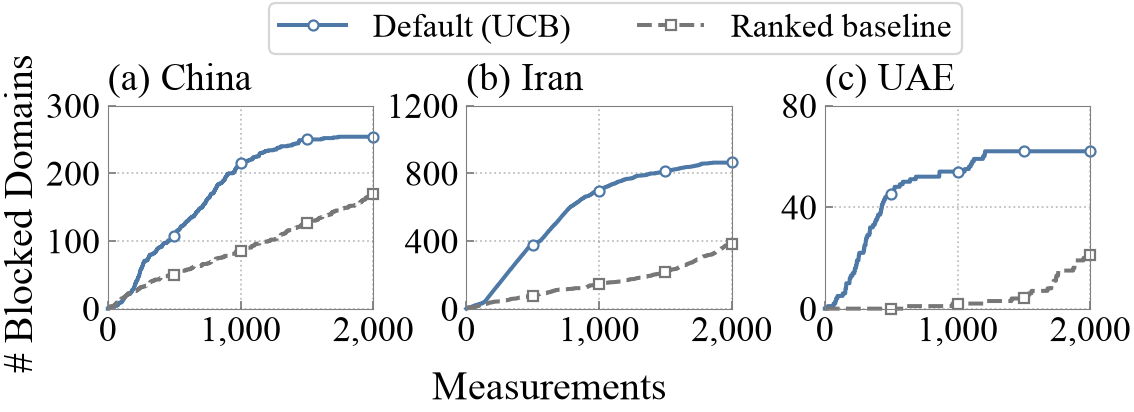

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(6.9, 2.7))
for panel, (ax, country) in enumerate(zip(axes, FOCUS)):
    for config in ["exp5", "baseline"]:
        d = master[master["country"].eq(country) & master["config"].eq(config)]
        ax.plot(np.r_[0, d["step"]], np.r_[0, d["cumulative_blocked"]],
                color=COLORS[config], linestyle=LINES[config], marker=MARKERS[config],
                markevery=[500, 1000, 1500, 2000], markersize=4.5, markerfacecolor="white",
                markeredgewidth=1.0, linewidth=1.8, clip_on=False, label=LABELS[config])
    ax.set(xlim=(0, 2000), ylim=YLIMS[country],
           xticks=[0, 1000, 2000], yticks=YTICKS[country])
    ax.set_xticklabels(["0", "1,000", "2,000"])
    ax.set_title(f"({chr(97 + panel)}) {COUNTRY_TITLES[country]}", loc="left", pad=7)
    format_axes(ax)
    ax.set_axisbelow(True)
fig.legend(*axes[0].get_legend_handles_labels(), ncol=2, loc="upper center",
           bbox_to_anchor=(.56, 1.025), frameon=True, edgecolor="#cccccc", borderpad=.3)
fig.supxlabel("Measurements", y=.05, fontsize=PAPER_AXIS_LABEL_SIZE)
fig.supylabel("# Blocked Domains", x=.006, fontsize=PAPER_AXIS_LABEL_SIZE)
fig.subplots_adjust(left=.1, right=.99, bottom=.28, top=.75, wspace=.35)
for extension in ["pdf", "png"]:
    fig.savefig(FIGS / f"01_default_baseline.{extension}", bbox_inches="tight", pad_inches=.025)
plt.show()

## 5.2 Policies

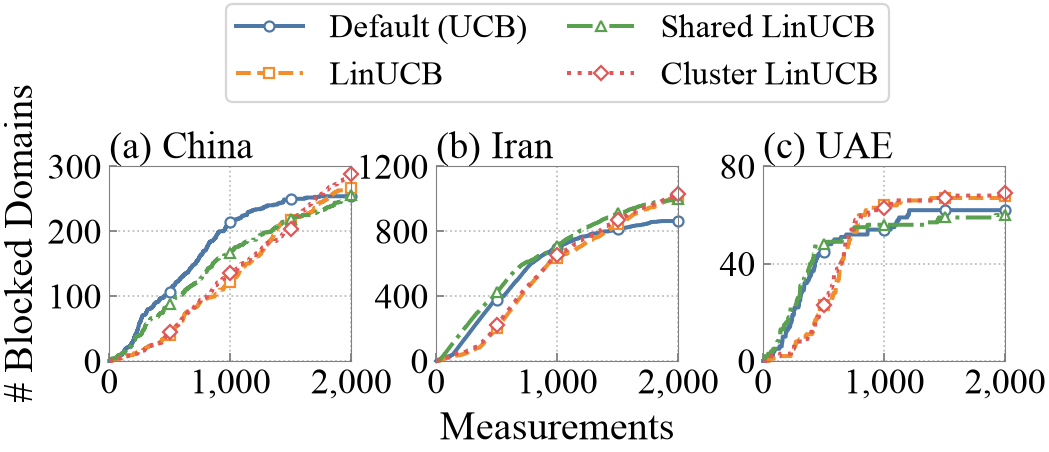

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(7, 3.2))
for panel, (ax, country) in enumerate(zip(axes, FOCUS)):
    for config in ["exp5", "exp2", "exp3", "exp4"]:
        d = master[master["country"].eq(country) & master["config"].eq(config)]
        ax.plot(np.r_[0, d["step"]], np.r_[0, d["cumulative_blocked"]],
                color=COLORS[config], linestyle=LINES[config], marker=MARKERS[config],
                markevery=[500, 1000, 1500, 2000], markersize=4.5, markerfacecolor="white",
                markeredgewidth=1.0, linewidth=1.8, clip_on=False, label=LABELS[config])
    ax.set(xlim=(0, 2000), ylim=YLIMS[country],
           xticks=[0, 1000, 2000], yticks=YTICKS[country])
    ax.set_xticklabels(["0", "1,000", "2,000"])
    ax.set_title(f"({chr(97 + panel)}) {COUNTRY_TITLES[country]}", loc="left", pad=2)
    format_axes(ax)
    ax.set_axisbelow(True)
fig.legend(*axes[0].get_legend_handles_labels(), ncol=2, loc="upper center",
           bbox_to_anchor=(.5, 1), frameon=True, edgecolor="#cccccc", borderpad=.3,
           columnspacing=1.2, handlelength=2.0)
fig.supxlabel("Measurements", y=0.1, fontsize=PAPER_AXIS_LABEL_SIZE)
fig.supylabel("# Blocked Domains", x=.006, fontsize=PAPER_AXIS_LABEL_SIZE)
fig.subplots_adjust(left=.1, right=.9, bottom=.27, top=.65, wspace=.35)
for extension in ["pdf", "png"]:
    fig.savefig(FIGS / f"02_policy_comparison.{extension}", bbox_inches="tight", pad_inches=.025)
plt.show()

In [7]:
policy_metrics = summary[summary["config"].isin(["exp5", "exp2", "exp3", "exp4"])].merge(
    summary[summary["config"].eq("exp5")][["country", "flagged"]].rename(
        columns={"flagged": "default_flagged"}), on="country", validate="many_to_one")
policy_metrics["gain_over_default_pct"] = 100 * (
    policy_metrics["flagged"] / policy_metrics["default_flagged"].replace(0, np.nan) - 1)
policy_metrics.to_csv(TABLES / "policy_endpoint_gains.csv", index=False)

# Arm allocation and domain membership are different views of overlapping categories.
arm_summary = master.groupby(["country", "config", "arm"]).agg(
    selected=("target", "size"), flagged=("blocked", "sum"),
    first_step=("step", "min"), last_step=("step", "max"), mean_reward=("reward", "mean")
).reset_index()
arm_summary["flag_rate"] = arm_summary["flagged"] / arm_summary["selected"]
arm_summary.to_csv(TABLES / "arm_allocation.csv", index=False)
membership = master[["country", "config", "target", "step", "blocked", "categories"]].explode("categories")
membership_summary = membership.groupby(["country", "config", "categories"]).agg(
    measured=("target", "nunique"), flagged=("blocked", "sum"), last_step=("step", "max")
).reset_index().merge(candidate_sizes, on="categories", how="left", validate="many_to_one")
membership_summary["inventory_coverage"] = membership_summary["measured"] / membership_summary["candidates"]
membership_summary.to_csv(TABLES / "category_inventory_coverage.csv", index=False)

exhaustion_rows = []
for (country, config, category), d in membership.groupby(["country", "config", "categories"]):
    n = candidate_sizes.loc[category]
    if d["target"].nunique() == n:
        exhaustion_rows.append({"country": country, "config": config, "category": category,
                                "candidates": n, "fully_observed_at": int(d["step"].max())})
exhaustion = pd.DataFrame(exhaustion_rows)
exhaustion.to_csv(TABLES / "fully_observed_categories.csv", index=False)
display(policy_metrics[["country_code", "policy", "flagged", "gain_over_default_pct"]])
display(arm_summary[arm_summary["country"].eq("Iran") & arm_summary["config"].isin(["exp5", "exp6"])]
        .sort_values(["config", "selected"], ascending=[True, False]).groupby("config").head(6))
display(exhaustion[exhaustion["country"].eq("Iran") & exhaustion["config"].eq("exp5")])

,country_code,policy,flagged,gain_over_default_pct
0,CN,LinUCB,266,4.724
1,CN,Shared LinUCB,256,0.787
2,CN,Cluster LinUCB,289,13.780
3,CN,Default (UCB),254,0.000
4,DE,LinUCB,0,NaN
5,DE,Shared LinUCB,0,NaN
6,DE,Cluster LinUCB,0,NaN
7,DE,Default (UCB),0,NaN
8,IR,LinUCB,1010,16.898
9,IR,Shared LinUCB,996,15.278


,country,config,arm,selected,flagged,first_step,last_step,mean_reward,flag_rate
1446,Iran,exp5,Ecommerce,421,61,47,1863,0.138,0.145
1493,Iran,exp5,Pornography,329,321,8,467,0.926,0.976
1505,Iran,exp5,Social Networks,239,210,60,791,0.798,0.879
1428,Iran,exp5,Advertisements,132,17,62,1460,0.126,0.129
1488,Iran,exp5,Personal Blogs,114,35,76,1196,0.286,0.307
1465,Iran,exp5,Information Security,103,2,97,2000,0.019,0.019
1610,Iran,exp6,Video Streaming,498,219,1,1549,0.404,0.440
1588,Iran,exp6,Pornography,330,320,50,494,0.870,0.970
1600,Iran,exp6,Social Networks,236,208,78,775,0.800,0.881
1583,Iran,exp6,Personal Blogs,110,34,71,1811,0.287,0.309


,country,config,category,candidates,fully_observed_at
523,Iran,exp5,Adult Themes,38,541
524,Iran,exp5,Advertisements,139,1460
525,Iran,exp5,Anonymizer,5,470
526,Iran,exp5,Auctions & Marketplaces,100,1336
527,Iran,exp5,Audio Streaming,54,1073
528,Iran,exp5,Body Art,1,14
529,Iran,exp5,Cartoons & Anime,21,822
530,Iran,exp5,Comic Books,32,1273
531,Iran,exp5,Digital Postcards,1,86
532,Iran,exp5,Ecommerce,431,1863


## 5.3 Rewards

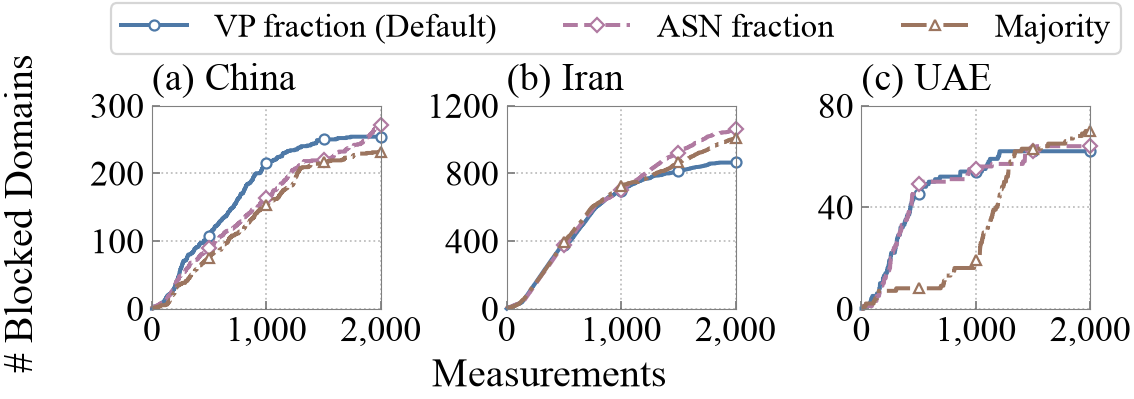

In [8]:
reward_labels = {"exp5": "VP fraction (Default)", "exp6": "ASN fraction", "exp7": "Majority"}
fig, axes = plt.subplots(1, 3, figsize=(6.9, 2.7))
for panel, (ax, country) in enumerate(zip(axes, FOCUS)):
    for config in ["exp5", "exp6", "exp7"]:
        d = master[master["country"].eq(country) & master["config"].eq(config)]
        ax.plot(np.r_[0, d["step"]], np.r_[0, d["cumulative_blocked"]],
                color=COLORS[config], linestyle=LINES[config], marker=MARKERS[config],
                markevery=[500, 1000, 1500, 2000], markersize=4.5, markerfacecolor="white",
                markeredgewidth=1.0, linewidth=1.8, clip_on=False, label=reward_labels[config])
    ax.set(xlim=(0, 2000), ylim=YLIMS[country],
           xticks=[0, 1000, 2000], yticks=YTICKS[country])
    ax.set_xticklabels(["0", "1,000", "2,000"])
    ax.set_title(f"({chr(97 + panel)}) {COUNTRY_TITLES[country]}", loc="left", pad=7)
    format_axes(ax)
    ax.set_axisbelow(True)
fig.legend(*axes[0].get_legend_handles_labels(), ncol=3, loc="upper center",
           bbox_to_anchor=(.56, 1.025), frameon=True, edgecolor="#cccccc", borderpad=.3)
fig.supxlabel("Measurements", y=.08, fontsize=PAPER_AXIS_LABEL_SIZE)
fig.supylabel("# Blocked Domains", x=.006, fontsize=PAPER_AXIS_LABEL_SIZE)
fig.subplots_adjust(left=.14, right=.99, bottom=.28, top=.75, wspace=.55)
for extension in ["pdf", "png"]:
    fig.savefig(FIGS / f"03_reward_comparison.{extension}", bbox_inches="tight", pad_inches=.025)
plt.show()

### Reward comparison table

Show all seven countries at 500 and 2,000 completed targets. Counts use the same blocking flag. A zero can still include blocking reported by a minority of VPs; reward sums have different meanings across configurations.

In [ ]:
reward_configs = ["exp5", "exp6", "exp7"]
reward_budgets = [500, 2000]
reward_checkpoints = checkpoints[checkpoints["config"].isin(reward_configs) &
    checkpoints["budget"].isin(reward_budgets)].copy()
assert reward_checkpoints["completed"].eq(reward_checkpoints["budget"]).all()
assert len(reward_checkpoints) == len(COUNTRIES) * 6
reward_checkpoints[["country", "config", "budget", "completed", "flagged"]].to_csv(
    TABLES / "reward_checkpoint_counts.csv", index=False)
reward_table = reward_checkpoints.pivot(index="country", columns=["config", "budget"],
    values="flagged").reindex(index=COUNTRIES,
    columns=pd.MultiIndex.from_product([reward_configs, reward_budgets])).astype(int)
display(reward_table)

# Keep one reporting threshold across all three training rewards.
reward_table_tex = [
    r"\begin{table}[t]",
    r"  \centering",
    r"  \caption{Blocked domains found by UCB with each reward after 500 and 2,000 completed targets. VP fraction is Default. A domain counts as blocked only when more than half of its usable VP votes indicate blocking. Zero does not rule out blocking reported by a minority of VPs. Bold marks the largest positive count per country and budget.}",
    r"  \label{tab:results_rewards}",
    r"  \small",
    r"  \setlength{\tabcolsep}{3pt}",
    r"  \renewcommand{\arraystretch}{1.15}",
    r"  \begin{tabular}{lrrrrrr}",
    r"    \hline",
    r"    & \multicolumn{2}{c}{VP fraction} & \multicolumn{2}{c}{ASN fraction} & \multicolumn{2}{c}{Majority} \\",
    r"    \cline{2-7}",
    r"    Country & 500 & 2,000 & 500 & 2,000 & 500 & 2,000 \\",
    r"    \hline",
]
for country in COUNTRIES:
    entries = []
    for config in reward_configs:
        for budget in reward_budgets:
            value = int(reward_table.loc[country, (config, budget)])
            maximum = max(int(reward_table.loc[country, (c, budget)]) for c in reward_configs)
            entry = f"{value:,}"
            entries.append(r"\textbf{" + entry + "}" if value > 0 and value == maximum else entry)
    reward_table_tex.append("    " + COUNTRY_TITLES.get(country, country.replace("_", " ")) + " & " + " & ".join(entries) + r" \\")
reward_table_tex += [r"    \hline", r"  \end{tabular}", r"\end{table}"]
reward_table_tex = "\n".join(reward_table_tex) + "\n"
(TABLES / "reward_comparison_table.tex").write_text(reward_table_tex)
print(reward_table_tex)


\begin{table}[t]
  \centering
  \caption{Blocked domains found by UCB with each reward after 500 and 2,000 completed targets. VP fraction is Default. A domain counts as blocked only when more than half of its usable VP votes indicate blocking. Zero does not rule out blocking reported by a minority of VPs. Bold marks the largest positive count per country and budget.}
  \label{tab:results_rewards}
  \small
  \setlength{\tabcolsep}{3pt}
  \renewcommand{\arraystretch}{1.15}
  \begin{tabular}{lrrrrrr}
    \hline
    & \multicolumn{2}{c}{VP fraction} & \multicolumn{2}{c}{ASN fraction} & \multicolumn{2}{c}{Majority} \\
    \cline{2-7}
    Country & 500 & 2,000 & 500 & 2,000 & 500 & 2,000 \\
    \hline
    China & \textbf{107} & 254 & 90 & \textbf{271} & 75 & 232 \\
    Germany & 0 & 0 & 0 & 0 & 0 & 0 \\
    Iran & 374 & 864 & 375 & \textbf{1,060} & \textbf{392} & 1,009 \\
    Thailand & 0 & 0 & 0 & 0 & 0 & 0 \\
    Turkey & 0 & 0 & 0 & 0 & 0 & 0 \\
    UAE & 45 & 62 & \textbf{49} & 64 & 8 & 

exp5      exp6       exp7      
                     500  2000 500   2000 500   2000
country                                             
China                 107  254   90   271   75   232
Germany                 0    0    0     0    0     0
Iran                  374  864  375  1060  392  1009
Thailand                0    0    0     0    0     0
Turkey                  0    0    0     0    0     0
United_Arab_Emirates   45   62   49    64    8    70
Vietnam                 0    0    0     0    0     0

## Feedback that the reporting threshold hides

,Zero logged reward,Positive reward only,Majority-positive,positive_targets,median_positive,maximum
country,,,,,,
China,1361,385,254,639,0.030,1.000
Germany,1613,387,0,387,0.010,0.040
Iran,1092,44,864,908,0.920,1.000
Thailand,1653,347,0,347,0.010,0.060
Turkey,1558,442,0,442,0.050,0.220
United_Arab_Emirates,1104,834,62,896,0.090,0.720
Vietnam,1226,774,0,774,0.060,0.110


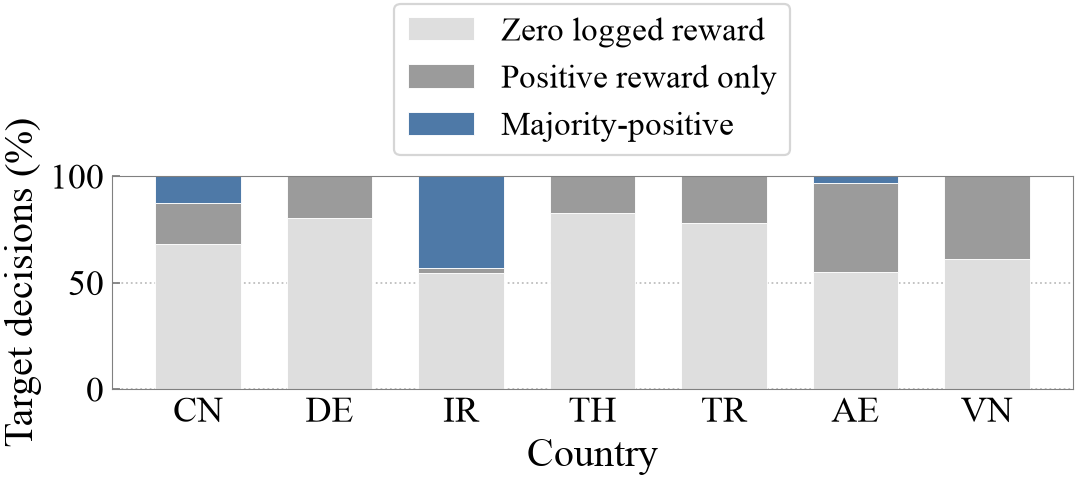

In [9]:
default = master[master["config"].eq("exp5")].copy()
default["feedback_type"] = np.select(
    [default["blocked"].eq(1), default["reward"].gt(0)],
    ["Majority-positive", "Positive reward only"], default="Zero logged reward")
feedback_counts = pd.crosstab(default["country"], default["feedback_type"]).reindex(
    index=COUNTRIES, columns=["Zero logged reward", "Positive reward only", "Majority-positive"]).fillna(0)
positive_stats = default[default["reward"].gt(0)].groupby("country")["reward"].agg(
    positive_targets="size", median_positive="median", maximum="max")
feedback_counts.join(positive_stats).to_csv(TABLES / "default_feedback.csv")
display(feedback_counts.join(positive_stats))

fig, ax = plt.subplots(figsize=(6.9, 3.2))
bottom = np.zeros(len(COUNTRIES))
for kind, color in zip(feedback_counts.columns, ["#dedede", "#9b9b9b", COLORS["exp5"]]):
    values = feedback_counts[kind].to_numpy() / 2000 * 100
    ax.bar(np.arange(7), values, bottom=bottom, color=color, width=.65,
           label=kind, edgecolor="white", linewidth=.4)
    bottom += values
ax.set(xticks=np.arange(7), xticklabels=[SHORT[c] for c in COUNTRIES],
       ylim=(0, 100), ylabel="Target decisions (%)", xlabel="Country")
format_axes(ax)
ax.xaxis.grid(False)
ax.set_axisbelow(True)
ax.legend(ncol=1, loc="lower center", bbox_to_anchor=(.5, 1.02),
          frameon=True, fontsize=PAPER_LEGEND_SIZE)
fig.tight_layout(pad=.5)
for extension in ["pdf", "png"]:
    fig.savefig(FIGS / f"supp_default_feedback.{extension}", bbox_inches="tight", pad_inches=.025)
plt.show()

## Category allocation and inventory

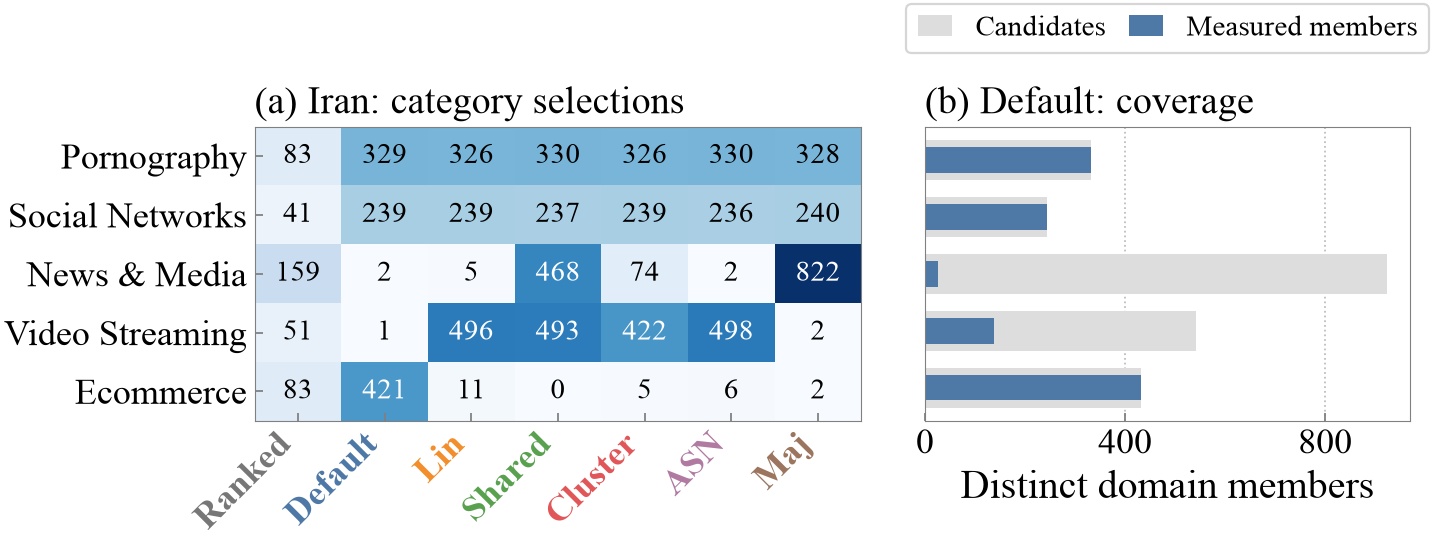

,measured,candidates,flagged,inventory_coverage
categories,,,,
Pornography,331,331,321,1.000
Social Networks,245,245,215,1.000
News & Media,27,924,6,0.029
Video Streaming,138,541,84,0.255
Ecommerce,431,431,64,1.000


In [10]:
iran_configs = ["baseline", "exp5", "exp2", "exp3", "exp4", "exp6", "exp7"]
topics = ["Pornography", "Social Networks", "News & Media", "Video Streaming", "Ecommerce"]
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.8), gridspec_kw={"width_ratios": [1.25, 1]})
allocation_matrix = arm_summary[arm_summary["country"].eq("Iran")].pivot(
    index="arm", columns="config", values="selected").reindex(index=topics, columns=iran_configs).fillna(0)
im = axes[0].imshow(allocation_matrix.to_numpy(), cmap="Blues", aspect="auto", vmin=0, vmax=700)
for i in range(len(topics)):
    for j in range(len(iran_configs)):
        value = int(allocation_matrix.iloc[i, j])
        axes[0].text(j, i, str(value), ha="center", va="center",
                     fontsize=13, color="white" if value > 400 else "black")
axes[0].set(xticks=np.arange(7), yticks=np.arange(len(topics)), yticklabels=topics)
axes[0].set_xticklabels(["Ranked", "Default", "Lin", "Shared", "Cluster", "ASN", "Maj"],
                       rotation=45, ha="right")
for tick, config in zip(axes[0].get_xticklabels(), iran_configs):
    tick.set_color(COLORS[config])
    tick.set_fontweight("bold")
axes[0].set_title("(a) Iran: category selections", loc="left")
coverage_matrix = membership_summary[
    membership_summary["country"].eq("Iran") & membership_summary["config"].eq("exp5")
].set_index("categories").reindex(topics)
x = np.arange(len(topics))
axes[1].barh(x, coverage_matrix["candidates"], color="#dddddd", height=.7, label="Candidates")
axes[1].barh(x, coverage_matrix["measured"], color=COLORS["exp5"], height=.45, label="Measured members")
axes[1].set(yticks=x, yticklabels=[], xlabel="Distinct domain members")
axes[1].invert_yaxis()
axes[1].xaxis.set_major_locator(MaxNLocator(3))
axes[1].set_axisbelow(True)
axes[1].set_title("(b) Default: coverage", loc="left")
axes[1].legend(loc="lower center", bbox_to_anchor=(.5, 1.20), ncol=2, fontsize=13,
               columnspacing=.8, handlelength=1.2)
for ax in axes:
    format_axes(ax)
axes[0].grid(False)  # The cell colors already encode the counts.
axes[1].yaxis.grid(False)
fig.tight_layout(pad=.6, w_pad=1)
for extension in ["pdf", "png"]:
    fig.savefig(FIGS / f"supp_iran_allocation.{extension}", bbox_inches="tight", pad_inches=.025)
plt.show()
display(coverage_matrix[["measured", "candidates", "flagged", "inventory_coverage"]])

## When category arms are selected

Baseline and Default UCB in China. Use Default's three arms with the most blocked discoveries: Video Streaming, Photography, and Pornography. Boxes summarize completion steps; points use the saved blocking flag. Counts give directly selected targets, not all overlapping memberships. The text also uses Iran's Pornography arm to explain the allocation difference.


,arm,config,selected,flagged,median_step,step_iqr
70,Video Streaming,baseline,51,16,"1,273.000","1,180.500"
369,Video Streaming,exp5,535,112,643.000,267.000
49,Photography,baseline,16,8,"1,244.500","1,008.000"
345,Photography,exp5,83,42,234.000,41.000
51,Pornography,baseline,83,9,"1,733.000",332.000
347,Pornography,exp5,326,23,"1,181.500",162.500


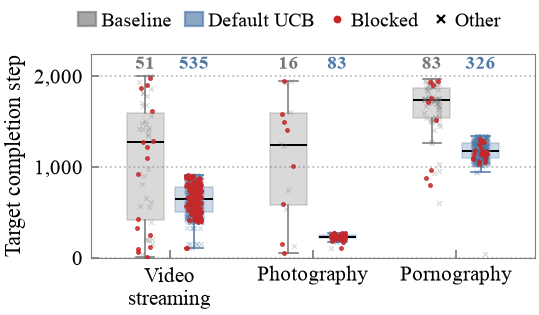

In [31]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.backends.backend_pdf import PdfPages
import shutil
import textwrap

selection_timing = master.groupby(["country", "config", "arm"]).agg(
    selected=("target", "nunique"), flagged=("blocked", "sum"),
    mean_reward=("reward", "mean"), first_step=("step", "min"),
    q1_step=("step", lambda s: s.quantile(.25)), median_step=("step", "median"),
    q3_step=("step", lambda s: s.quantile(.75)), last_step=("step", "max")
).reset_index()
selection_timing["step_iqr"] = selection_timing["q3_step"] - selection_timing["q1_step"]
selection_timing.to_csv(TABLES / "category_selection_timing.csv", index=False)
timing_country = "China"
focus_arms = ["Video Streaming", "Photography", "Pornography"]
timing_configs = ["baseline", "exp5"]
timing_labels = ["Baseline", "Default UCB"]
focus_timing = selection_timing[selection_timing["country"].eq(timing_country) &
    selection_timing["config"].isin(timing_configs) &
    selection_timing["arm"].isin(focus_arms)].copy()
focus_timing["category_order"] = focus_timing["arm"].map(dict(zip(focus_arms, range(3))))
focus_timing["method_order"] = focus_timing["config"].map(dict(zip(timing_configs, range(len(timing_configs)))))
focus_timing = focus_timing.sort_values(["category_order", "method_order"]).drop(
    columns=["category_order", "method_order"])
assert len(focus_timing) == 6
default_top_arms = selection_timing[selection_timing["country"].eq(timing_country) &
    selection_timing["config"].eq("exp5")].nlargest(3, "flagged")["arm"].tolist()
assert focus_arms == default_top_arms
focus_timing.to_csv(TABLES / "category_timing_main.csv", index=False)
display(focus_timing[["arm", "config", "selected", "flagged", "median_step", "step_iqr"]])

# Category choices use blocked discovery counts in the observed Default trace.
BLOCKED_POINT_COLOR = "#C62828"
fig, ax = plt.subplots(figsize=(3.45, 2.05))
rng = np.random.default_rng(0)
for offset, config in zip([-.17, .17], timing_configs):
    color = COLORS[config]
    for i, arm in enumerate(focus_arms):
        d = master[master["country"].eq(timing_country) & master["config"].eq(config) & master["arm"].eq(arm)]
        if len(d) >= 5:
            ax.boxplot([d["step"].to_numpy()], positions=[i + offset], widths=.26,
                       patch_artist=True, showfliers=False,
                       boxprops={"facecolor": color, "edgecolor": color, "alpha": .28, "linewidth": .7},
                       medianprops={"color": "black", "linewidth": .9},
                       whiskerprops={"color": color, "linewidth": .7},
                       capprops={"color": color, "linewidth": .7})
        positions = i + offset + rng.uniform(-.055, .055, len(d))
        for positive, marker, alpha in [(False, "x", .32), (True, "o", .85)]:
            keep = d["blocked"].eq(int(positive)).to_numpy()
            ax.scatter(positions[keep], d.loc[keep, "step"],
                       c=BLOCKED_POINT_COLOR if positive else color, marker=marker,
                       s=3 if positive else 4.5, linewidths=.45, alpha=alpha,
                       zorder=4 if positive else 3)
        ax.text(i + offset, 2130, str(len(d)), ha="center", va="center",
                fontsize=8.5, color=color, fontweight="bold")
ax.set(xlim=(-.55, 2.55), ylim=(0, 2240), yticks=[0, 1000, 2000],
       xticks=np.arange(3), ylabel="Target completion step")
format_axes(ax)
ax.tick_params(axis="both", labelsize=9.5)
ax.yaxis.label.set_size(10)
ax.xaxis.grid(False)
ax.set_xticklabels(["Video\nstreaming", "Photography", "Pornography"], fontsize=9.5)
ax.set_yticklabels(["0", "1,000", "2,000"])
ax.set_axisbelow(True)
handles = [Patch(facecolor=COLORS[c], edgecolor=COLORS[c], alpha=.65, label=label)
           for c, label in zip(timing_configs, timing_labels)]
handles += [Line2D([], [], color=BLOCKED_POINT_COLOR, marker="o", markersize=2.5, linestyle="none", label="Blocked"),
            Line2D([], [], color="black", marker="x", markersize=3.5, linestyle="none", label="Other")]
fig.legend(handles=handles, ncol=4, loc="upper center", bbox_to_anchor=(.54, 1.025),
           frameon=False, fontsize=9.2, handlelength=.9, handletextpad=.25, columnspacing=.65)
fig.subplots_adjust(left=.18, right=.985, bottom=.22, top=.84)
for extension in ["pdf", "png"]:
    fig.savefig(FIGS / f"04_category_timing.{extension}", bbox_inches="tight", pad_inches=.025)
paper_figures = ANALYSIS.parent / "paper" / "figures"
paper_figures.mkdir(exist_ok=True)
shutil.copyfile(FIGS / "04_category_timing.pdf", paper_figures / "results_category_timing.pdf")
plt.show()


Preserved 8 category-timing comparisons.


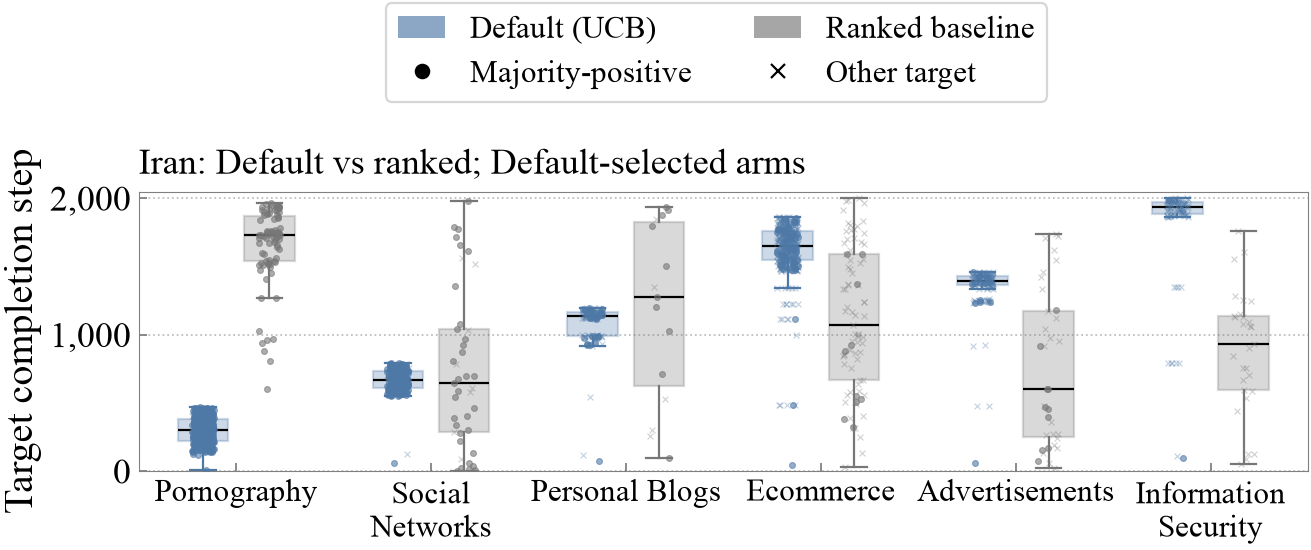

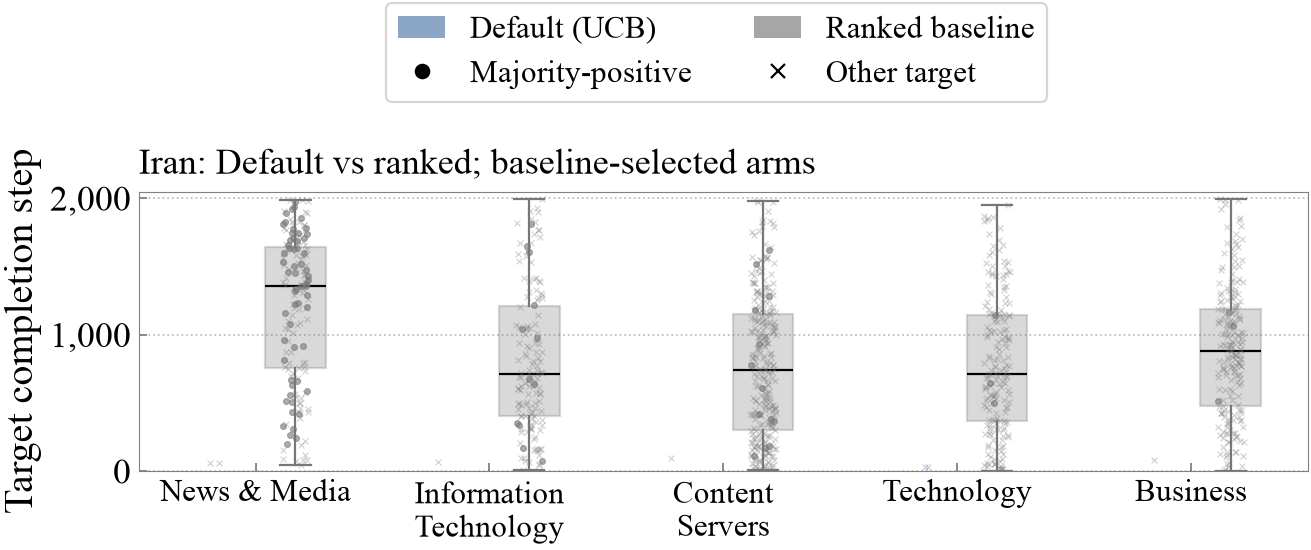

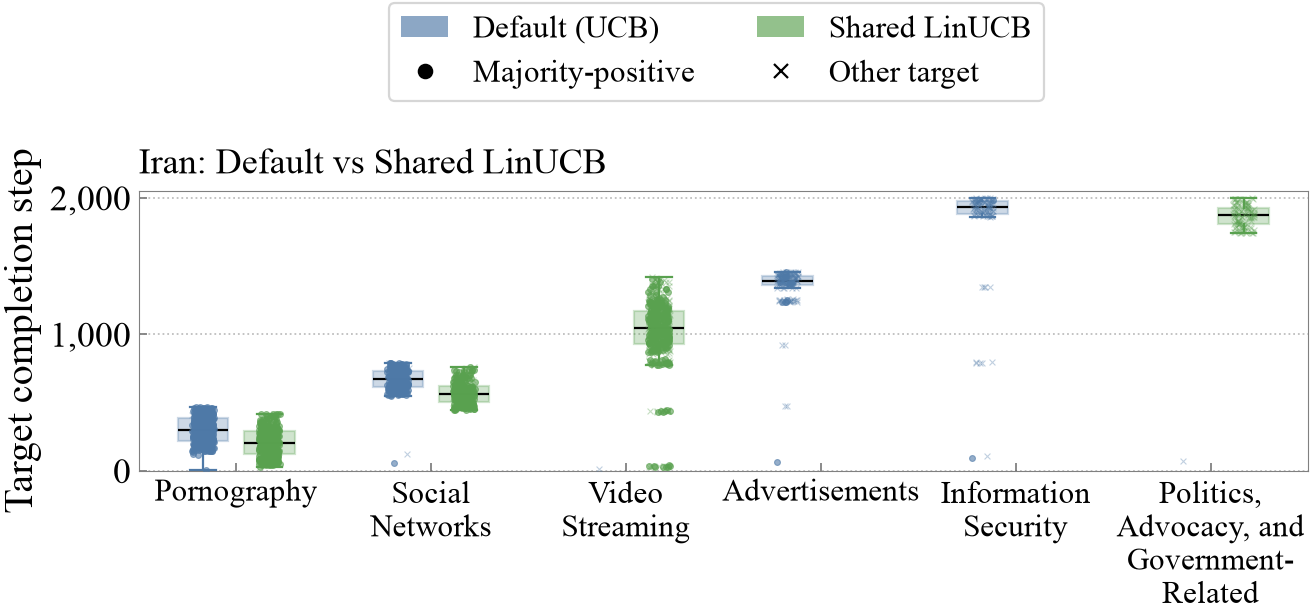

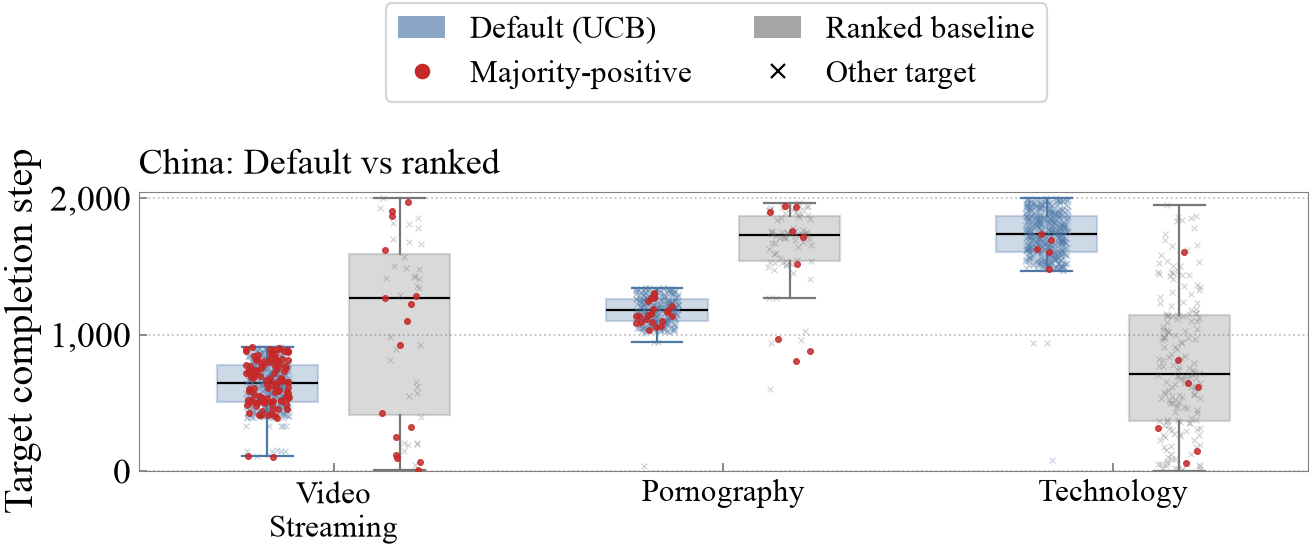

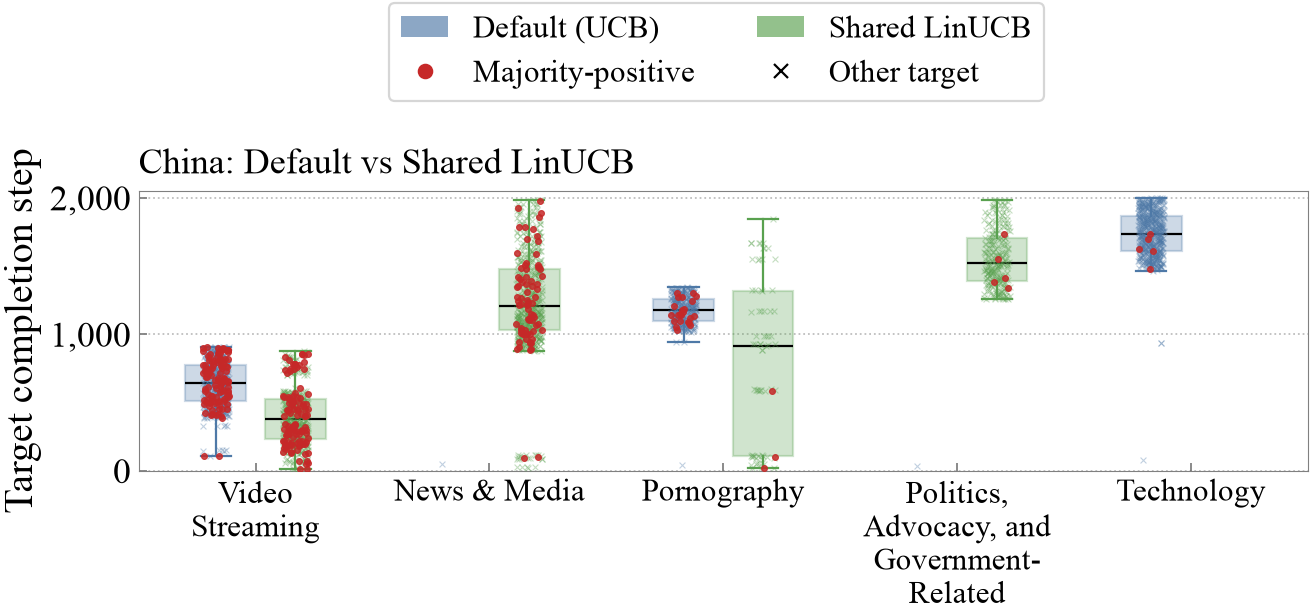

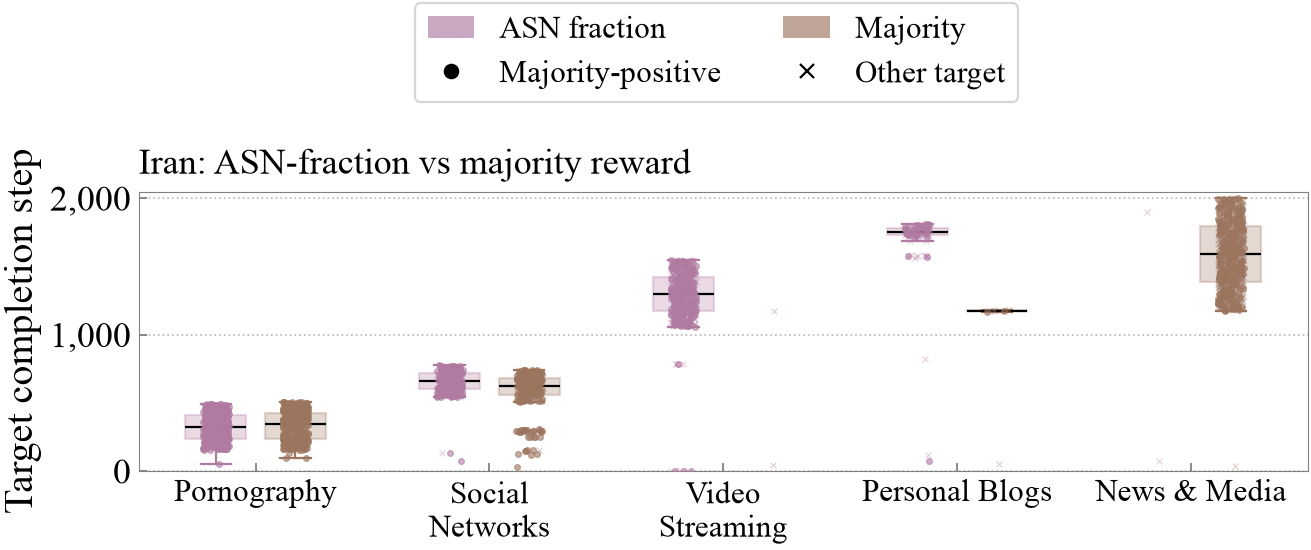

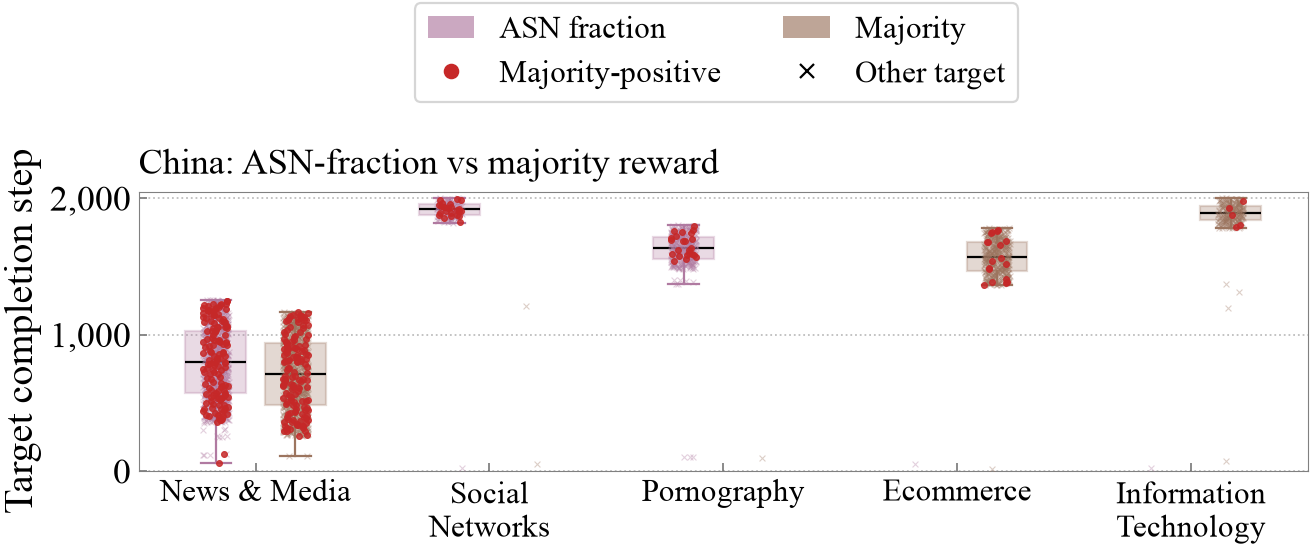

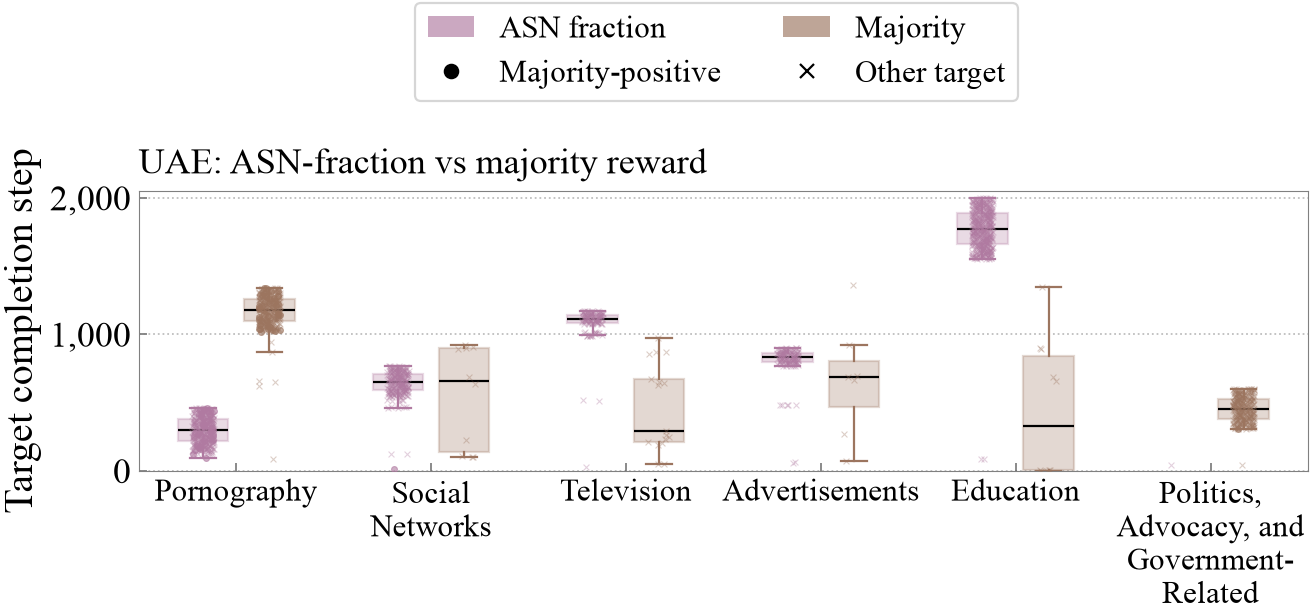

In [12]:
# Wider views retain the draft's high/low-reward and baseline-selected categories.
boxplot_cases = [
    ("Iran", ["exp5", "baseline"], ["exp5"], "Default vs ranked; Default-selected arms"),
    ("Iran", ["exp5", "baseline"], ["baseline"], "Default vs ranked; baseline-selected arms"),
    ("Iran", ["exp5", "exp3"], ["exp5", "exp3"], "Default vs Shared LinUCB"),
    ("China", ["exp5", "baseline"], ["exp5"], "Default vs ranked"),
    ("China", ["exp5", "exp3"], ["exp5", "exp3"], "Default vs Shared LinUCB"),
    ("Iran", ["exp6", "exp7"], ["exp6", "exp7"], "ASN-fraction vs majority reward"),
    ("China", ["exp6", "exp7"], ["exp6", "exp7"], "ASN-fraction vs majority reward"),
    ("United_Arab_Emirates", ["exp6", "exp7"], ["exp6", "exp7"], "ASN-fraction vs majority reward"),
]
boxplot_category_rows = []
with PdfPages(FIGS / "category_timing_diagnostics.pdf") as diagnostic_pdf:
    for case, (country, configs, selection_configs, title) in enumerate(boxplot_cases, start=1):
        # Preserve run order when a target appears in both compared traces.
        selection = pd.concat([master[master["country"].eq(country) & master["config"].eq(c)]
                               for c in selection_configs]).drop_duplicates("target")
        eligible = selection.groupby("arm").agg(n=("target", "nunique"), mean_reward=("reward", "mean"))
        eligible = eligible[eligible["n"].ge(100)].sort_values("mean_reward", ascending=False)
        arms = list(dict.fromkeys(list(eligible.index[:3]) + list(eligible.index[-3:])))
        for order, arm in enumerate(arms):
            boxplot_category_rows.append({"page": case, "country": country, "comparison": title,
                "arm": arm, "order": order, "selection_configs": ",".join(selection_configs),
                "eligible_targets": int(eligible.loc[arm, "n"]),
                "selection_mean_reward": float(eligible.loc[arm, "mean_reward"])})
        fig, ax = plt.subplots(figsize=(8.4, 3.8))
        rng = np.random.default_rng(0)
        for offset, config in [(-.17, configs[0]), (.17, configs[1])]:
            color = COLORS[config]
            for i, arm in enumerate(arms):
                d = master[master["country"].eq(country) & master["config"].eq(config) & master["arm"].eq(arm)]
                if len(d) >= 5:
                    ax.boxplot([d["step"].to_numpy()], positions=[i + offset], widths=.26,
                               patch_artist=True, showfliers=False,
                               boxprops={"facecolor": color, "edgecolor": color, "alpha": .28},
                               medianprops={"color": "black", "linewidth": 1},
                               whiskerprops={"color": color}, capprops={"color": color})
                positions = i + offset + rng.uniform(-.055, .055, len(d))
                for positive, marker, alpha in [(False, "x", .35), (True, "o", .60)]:
                    keep = d["blocked"].eq(int(positive)).to_numpy()
                    ax.scatter(positions[keep], d.loc[keep, "step"],
                               c=BLOCKED_POINT_COLOR if positive and country == "China" else color,
                               marker=marker, s=7, linewidths=.5,
                               alpha=.85 if positive and country == "China" else alpha,
                               zorder=4 if positive else 3)
        ax.set(xlim=(-.5, len(arms) - .5), ylim=(0, 2050), yticks=[0, 1000, 2000],
               xticks=np.arange(len(arms)), ylabel="Target completion step")
        format_axes(ax)
        ax.xaxis.grid(False)
        ax.set_xticklabels([textwrap.fill(a, width=14, break_long_words=False) for a in arms], fontsize=14)
        ax.set_yticklabels(["0", "1,000", "2,000"])
        ax.set_title(f"{COUNTRY_TITLES[country]}: {title}", loc="left", fontsize=16, pad=8)
        ax.set_axisbelow(True)
        handles = [Patch(facecolor=COLORS[configs[0]], alpha=.65, label=LABELS[configs[0]]),
                   Line2D([], [], color=BLOCKED_POINT_COLOR if country == "China" else "black",
                          marker="o", linestyle="none", label="Majority-positive"),
                   Patch(facecolor=COLORS[configs[1]], alpha=.65, label=LABELS[configs[1]]),
                   Line2D([], [], color="black", marker="x", linestyle="none", label="Other target")]
        fig.legend(handles=handles, ncol=2, loc="upper center", bbox_to_anchor=(.55, 1.025),
                   fontsize=14, columnspacing=2, handlelength=1.5)
        fig.subplots_adjust(left=.12, right=.99, bottom=.23, top=.69)
        diagnostic_pdf.savefig(fig, bbox_inches="tight", pad_inches=.025)
        fig.savefig(FIGS / f"boxplot_diagnostic_{case:02d}.png", bbox_inches="tight", pad_inches=.025)
        plt.show()
pd.DataFrame(boxplot_category_rows).to_csv(TABLES / "boxplot_category_selection.csv", index=False)
print("Preserved", len(boxplot_cases), "category-timing comparisons.")


## All-country endpoint table

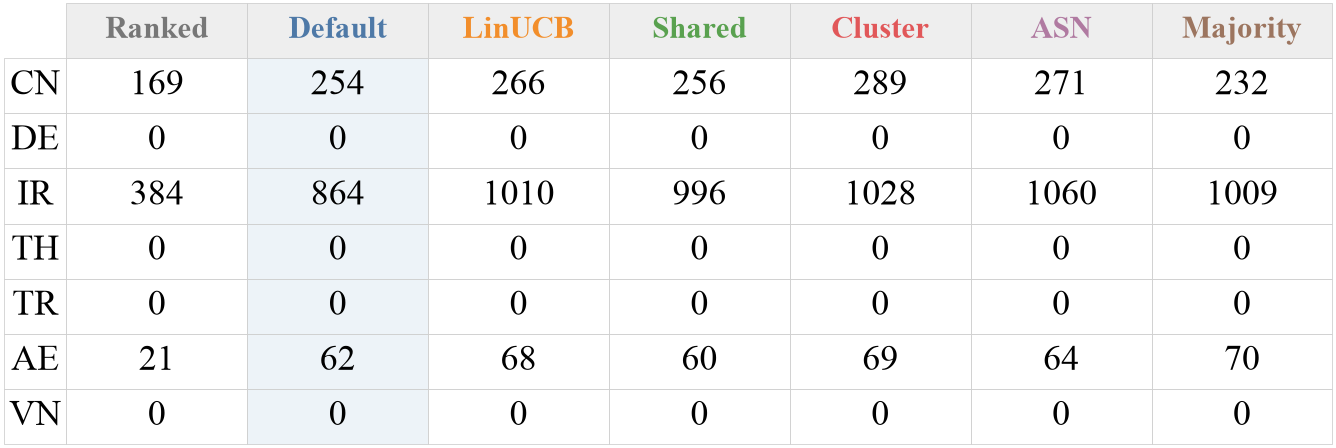

In [13]:
fig, ax = plt.subplots(figsize=(8.4, 2.8))
format_axes(ax)
ax.axis("off")
table = ax.table(
    cellText=endpoints.to_numpy(dtype=int),
    rowLabels=[SHORT[c] for c in COUNTRIES],
    colLabels=["Ranked", "Default", "LinUCB", "Shared", "Cluster", "ASN", "Majority"],
    cellLoc="center", rowLoc="center", bbox=[.035, 0, .965, 1])
table.auto_set_font_size(False)
table.set_fontsize(16)
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("#cccccc")
    cell.set_linewidth(.35)
    if row == 0:
        cell.set_facecolor("#eeeeee")
        cell.set_text_props(weight="bold", color=COLORS[CONFIGS[col]], fontsize=14)
    elif col == 1:
        cell.set_facecolor("#edf3f8")
fig.tight_layout(pad=.1)
for extension in ["pdf", "png"]:
    fig.savefig(FIGS / f"supp_all_country_endpoints.{extension}", bbox_inches="tight", pad_inches=.025)
plt.show()

## ASN observations on the Default target set

In [14]:
asn = pd.read_csv(DATA / "exp5_asns" / "asn_votes_exp5.csv",
                  dtype={"country": "category", "target": "category", "category": "category",
                         "asn": "category", "n_votes": "int32", "n_blocked": "int32"})
asn["country"] = asn["country"].astype(str).str.replace(" ", "_", regex=False).astype("category")
assert not asn.duplicated(["country", "target", "asn"]).any()
assert asn["n_votes"].gt(0).all()
assert asn["n_blocked"].between(0, asn["n_votes"]).all()
assert np.allclose(asn["vote_fraction"], asn["n_blocked"] / asn["n_votes"], atol=5.01e-5)
# The export rounds fractions to four decimals; use the integer counts.
asn["exported_vote_fraction"] = asn["vote_fraction"]
asn["vote_fraction"] = asn["n_blocked"] / asn["n_votes"]

asn_target = asn.groupby(["country", "target"], observed=True).agg(
    posthoc_votes=("n_votes", "sum"), posthoc_blocked=("n_blocked", "sum"),
    posthoc_asn_fraction=("vote_fraction", "mean"), asn_groups=("asn", "nunique"),
    asn_fraction_min=("vote_fraction", "min"), asn_fraction_max=("vote_fraction", "max"),
).reset_index()
asn_target["posthoc_vp_fraction"] = asn_target["posthoc_blocked"] / asn_target["posthoc_votes"]
asn_target["posthoc_flag"] = asn_target["posthoc_vp_fraction"].gt(.5).astype(int)
asn_target["normalization_gap"] = asn_target["posthoc_asn_fraction"] - asn_target["posthoc_vp_fraction"]

asn_match_rows = []
for country in COUNTRIES:
    raw_targets = set(asn_target.loc[asn_target["country"].eq(country), "target"])
    for config in CONFIGS:
        targets = set(master.loc[master["country"].eq(country) & master["config"].eq(config), "target"])
        asn_match_rows.append({"country": country, "config": config, "matched_targets": len(raw_targets & targets),
                              "same_target_set": raw_targets == targets})
asn_matches = pd.DataFrame(asn_match_rows)
assert asn_matches.loc[asn_matches["config"].eq("exp5"), "same_target_set"].all()
assert not asn_matches.loc[asn_matches["config"].ne("exp5"), "same_target_set"].any()
asn_matches.to_csv(TABLES / "asn_target_set_matches.csv", index=False)

asn_checked = asn_target.merge(
    default[["country", "target", "blocked", "reward", "vp_count"]],
    on=["country", "target"], validate="one_to_one")
assert len(asn_checked) == 14_000
assert asn_checked["posthoc_flag"].eq(asn_checked["blocked"]).all()
asn_checked["different_vote_count"] = asn_checked["posthoc_votes"].ne(asn_checked["vp_count"])
asn_checked["fraction_mismatch"] = (asn_checked["posthoc_vp_fraction"] - asn_checked["reward"]).abs().gt(.005001)
asn_checked["heterogeneous"] = (
    asn_checked["asn_fraction_max"] - asn_checked["asn_fraction_min"]).gt(.5)
asn_audit = asn_checked.groupby("country", observed=True).agg(
    targets=("target", "size"), vote_count_mismatches=("different_vote_count", "sum"),
    reward_mismatches=("fraction_mismatch", "sum"),
    majority_positive=("blocked", "sum"), heterogeneous_targets=("heterogeneous", "sum"),
    median_groups=("asn_groups", "median"),
    mean_vp_fraction=("posthoc_vp_fraction", "mean"),
    mean_asn_fraction=("posthoc_asn_fraction", "mean"),
    mean_gap=("normalization_gap", "mean"))
asn_audit.to_csv(TABLES / "asn_audit.csv")
asn_checked.to_csv(TABLES / "default_asn_target_summary.csv", index=False)
display(asn_audit)

asn_checked["asn_reweighted_flag"] = asn_checked["posthoc_asn_fraction"].gt(.5)
asn_checked["flag_changes"] = asn_checked["posthoc_flag"].ne(asn_checked["asn_reweighted_flag"])
asn_weighting = asn_checked.groupby("country", observed=True).agg(
    targets=("target", "size"), flag_changes=("flag_changes", "sum"),
    median_asns=("asn_groups", "median"),
    mean_vp_fraction=("posthoc_vp_fraction", "mean"),
    mean_asn_fraction=("posthoc_asn_fraction", "mean"))
asn_weighting = asn_weighting.join(asn.groupby("country", observed=True).agg(
    min_votes_per_asn_target=("n_votes", "min"), max_votes_per_asn_target=("n_votes", "max")))
asn_weighting.to_csv(TABLES / "asn_weighting_comparison.csv")
flagged_weighting = asn_checked[asn_checked["blocked"].eq(1)].groupby("country", observed=True).agg(
    targets=("target", "size"), mean_vp_fraction=("posthoc_vp_fraction", "mean"),
    mean_asn_fraction=("posthoc_asn_fraction", "mean"), flag_changes=("flag_changes", "sum"))
flagged_weighting.to_csv(TABLES / "asn_weighting_majority_positive.csv")
display(asn_weighting)
display(flagged_weighting)

# Add Default-only diagnostics without multiplying master rows.
asn_for_master = asn_target.copy()
asn_for_master["config"] = "exp5"
master = master.merge(asn_for_master, on=["country", "target", "config"], how="left", validate="one_to_one")
assert len(master) == 98_000
master.to_csv(OUT / "master.csv.gz", index=False)
print("Saved master with posthoc ASN fields for Default only.")
print("Different denominators/fractions remain explicit; no reward overwrites.")

Saved master with posthoc ASN fields for Default only.
Different denominators/fractions remain explicit; no reward overwrites.


,targets,vote_count_mismatches,reward_mismatches,majority_positive,heterogeneous_targets,median_groups,mean_vp_fraction,mean_asn_fraction,mean_gap
country,,,,,,,,,
China,2000,928,127,254,614,81.000,0.127,0.122,-0.005
Germany,2000,1091,0,0,530,349.000,0.003,0.005,0.002
Iran,2000,14,6,864,641,12.000,0.403,0.403,0.000
Thailand,2000,12,1,0,18,40.000,0.002,0.001,-0.001
Turkey,2000,1,0,0,433,57.000,0.011,0.019,0.008
United_Arab_Emirates,2000,124,10,62,826,27.000,0.070,0.045,-0.024
Vietnam,2000,64,0,0,751,66.000,0.022,0.013,-0.009


,targets,flag_changes,median_asns,mean_vp_fraction,mean_asn_fraction,min_votes_per_asn_target,max_votes_per_asn_target
country,,,,,,,
China,2000,0,81.000,0.127,0.122,1,563
Germany,2000,0,349.000,0.003,0.005,1,407
Iran,2000,0,12.000,0.403,0.403,1,1
Thailand,2000,0,40.000,0.002,0.001,1,65
Turkey,2000,0,57.000,0.011,0.019,1,38
United_Arab_Emirates,2000,62,27.000,0.070,0.045,1,81
Vietnam,2000,0,66.000,0.022,0.013,1,35


,targets,mean_vp_fraction,mean_asn_fraction,flag_changes
country,,,,
China,254,0.964,0.916,0
Iran,864,0.925,0.925,0
United_Arab_Emirates,62,0.639,0.266,62


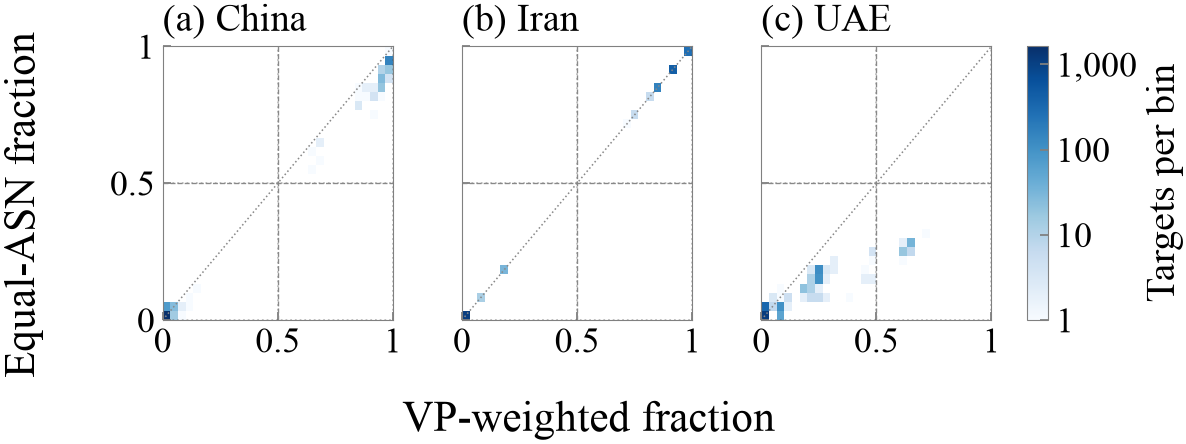

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(7.4, 3.0), sharex=True, sharey=True)
counts = []
for country in FOCUS:
    d = asn_checked[asn_checked["country"].eq(country)]
    hist, _, _ = np.histogram2d(d["posthoc_vp_fraction"], d["posthoc_asn_fraction"],
                                bins=np.linspace(0, 1, 31))
    counts.append(hist)
vmax = max(h.max() for h in counts)
for panel, (ax, country, hist) in enumerate(zip(axes, FOCUS, counts)):
    edges = np.linspace(0, 1, 31)
    mesh = ax.pcolormesh(edges, edges, np.ma.masked_equal(hist.T, 0),
                         cmap="Blues", norm=LogNorm(vmin=1, vmax=vmax), shading="flat")
    ax.plot([0, 1], [0, 1], color="#888888", linestyle=":", linewidth=.7)
    ax.axvline(.5, color="#888888", linestyle="--", linewidth=.6)
    ax.axhline(.5, color="#888888", linestyle="--", linewidth=.6)
    ax.set(xlim=(0, 1), ylim=(0, 1), xticks=[0, .5, 1], yticks=[0, .5, 1])
    ax.set_xticklabels(["0", "0.5", "1"])
    if panel == 0:
        ax.set_yticklabels(["0", "0.5", "1"])
    format_axes(ax)
    ax.set_title(f"({chr(97 + panel)}) {COUNTRY_TITLES[country]}", loc="left", pad=7)
fig.supxlabel("VP-weighted fraction", y=.01)
fig.supylabel("Equal-ASN fraction", x=.006)
fig.subplots_adjust(left=.14, right=.84, bottom=.26, top=.83, wspace=.30)
cax = fig.add_axes([.87, .26, .018, .57])
colorbar = fig.colorbar(mesh, cax=cax, label="Targets per bin", ticks=[1, 10, 100, 1000])
colorbar.set_ticklabels(["1", "10", "100", "1,000"])
format_axes(cax)
cax.grid(False)
for extension in ["pdf", "png"]:
    fig.savefig(FIGS / f"supp_asn_normalization.{extension}", bbox_inches="tight", pad_inches=.025)
plt.show()

## Blocking within sampled ASNs

Rows are overlapping category memberships across all Default selections, not the arm that selected a target. Each cell averages the exact blocked-vote fraction over measured domains in that ASN. Countries share the same rows and 0–100% scale; columns are ordered separately within each country. Gray means fewer than 20 domains. These are the postprocessed Default observations, not national blocking rates or a replay of online rewards.


In [16]:
ASN_CATEGORIES = ["Pornography", "Social Networks", "News & Media",
                  "Video Streaming", "Television", "Ecommerce"]
MIN_ASN_TARGETS = 20
asn_category_members = master.loc[master["config"].eq("exp5"),
    ["country", "target", "categories"]].explode("categories")
asn_category_members = asn_category_members[
    asn_category_members["categories"].isin(ASN_CATEGORIES)].copy()
assert not asn_category_members.duplicated(["country", "target", "categories"]).any()

asn_member_votes = asn[["country", "target", "asn", "n_votes", "n_blocked", "vote_fraction"]].merge(
    asn_category_members, on=["country", "target"], how="inner", validate="many_to_many")
asn_category = asn_member_votes.groupby(["country", "categories", "asn"], observed=True).agg(
    targets=("target", "nunique"), mean_fraction=("vote_fraction", "mean"),
    votes=("n_votes", "sum"), blocked_votes=("n_blocked", "sum")
).reset_index()
asn_category["pooled_fraction"] = asn_category["blocked_votes"] / asn_category["votes"]
asn_category["displayed"] = asn_category["targets"].ge(MIN_ASN_TARGETS)
asn_category.to_csv(TABLES / "asn_category_blocking.csv", index=False)

# One domain gets one weight in each ASN/category cell, regardless of its VP count.
asn_ordering = asn_category[asn_category["displayed"]].groupby(["country", "asn"], observed=True).agg(
    ordering_score=("mean_fraction", "mean"), displayed_categories=("categories", "nunique")
).reset_index()
all_asns = asn.groupby(["country", "asn"], observed=True).size().rename("target_groups").reset_index()
asn_ordering = all_asns.merge(asn_ordering, on=["country", "asn"], how="left", validate="one_to_one")
asn_ordering["asn_number"] = asn_ordering["asn"].astype(str).str.removeprefix("asn:").astype(int)
asn_ordering = asn_ordering.sort_values(["country", "ordering_score", "asn_number"],
                                      ascending=[True, False, True], na_position="last")
asn_ordering["column"] = asn_ordering.groupby("country", observed=True).cumcount()
asn_ordering.to_csv(TABLES / "asn_heatmap_columns.csv", index=False)

asn_heatmap_samples = asn_category_members.groupby(["country", "categories"], observed=True).agg(
    measured_domains=("target", "nunique")).reset_index()
asn_heatmap_samples = asn_heatmap_samples.merge(
    asn_category.groupby(["country", "categories"], observed=True).agg(
        represented_asns=("asn", "nunique"), displayed_asns=("displayed", "sum")),
    on=["country", "categories"], validate="one_to_one")
asn_heatmap_samples.to_csv(TABLES / "asn_heatmap_sample_sizes.csv", index=False)

display(asn_heatmap_samples.pivot(index="categories", columns="country", values="measured_domains")
        .reindex(ASN_CATEGORIES))
asn_heatmap_summary = asn_category[asn_category["displayed"]].groupby(
    ["country", "categories"], observed=True).agg(
    asns=("asn", "nunique"), minimum=("mean_fraction", "min"),
    median=("mean_fraction", "median"), maximum=("mean_fraction", "max"),
    zero_asns=("mean_fraction", lambda s: s.eq(0).sum()),
    above_half_asns=("mean_fraction", lambda s: s.gt(.5).sum())).reset_index()
asn_heatmap_summary.to_csv(TABLES / "asn_heatmap_summary.csv", index=False)
display(asn_heatmap_summary[asn_heatmap_summary["country"].isin(FOCUS) &
                            asn_heatmap_summary["categories"].eq("Pornography")])


country,China,Germany,Iran,Thailand,Turkey,United_Arab_Emirates,Vietnam
categories,,,,,,,
Pornography,331,28,331,23,7,331,331
Social Networks,74,245,245,245,245,245,45
News & Media,301,66,27,49,298,84,26
Video Streaming,541,165,138,105,541,167,23
Television,85,120,120,28,93,54,3
Ecommerce,29,75,431,64,28,37,47


,country,categories,asns,minimum,median,maximum,zero_asns,above_half_asns
2,China,Pornography,81,0.000,0.073,0.607,2,1
14,Iran,Pornography,12,0.408,0.964,0.970,0,11
31,United_Arab_Emirates,Pornography,27,0.000,0.000,0.949,16,4


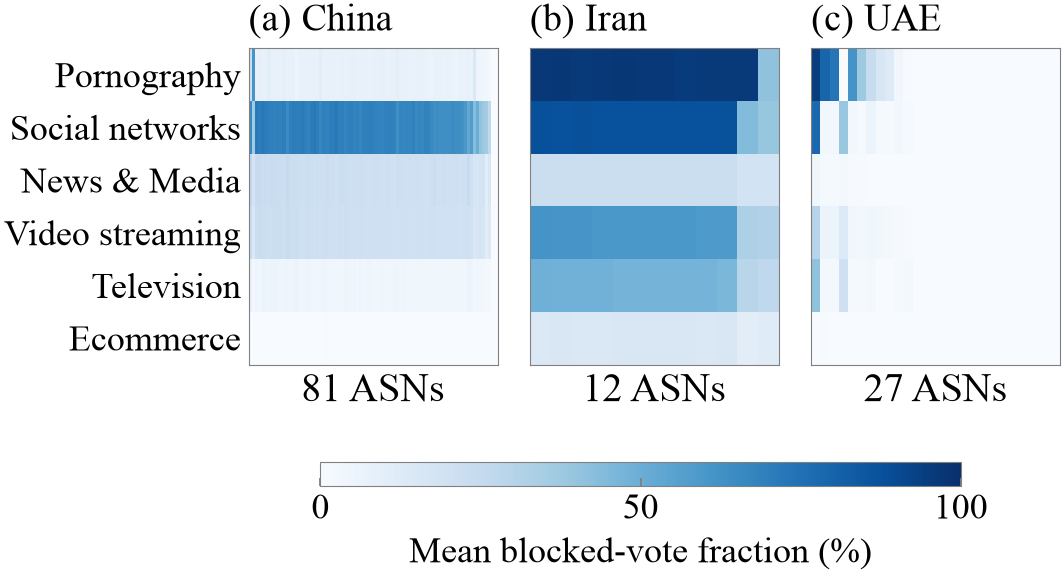

In [17]:
from matplotlib.colors import Normalize
from matplotlib.patches import Patch

asn_cmap = mpl.colormaps["Blues"].with_extremes(bad="#d9d9d9")
asn_norm = Normalize(vmin=0, vmax=100)
asn_row_labels = ["Pornography", "Social networks", "News & Media",
                  "Video streaming", "Television", "Ecommerce"]
fig, axes = plt.subplots(1, 3, figsize=(6.9, 3.8), sharey=True)
for panel, (ax, country) in enumerate(zip(axes, FOCUS)):
    order = asn_ordering.loc[asn_ordering["country"].eq(country), "asn"].tolist()
    cells = asn_category[asn_category["country"].eq(country)]
    rates = cells.pivot(index="categories", columns="asn", values="mean_fraction").reindex(
        index=ASN_CATEGORIES, columns=order)
    sizes = cells.pivot(index="categories", columns="asn", values="targets").reindex(
        index=ASN_CATEGORIES, columns=order)
    shown = rates.where(sizes.ge(MIN_ASN_TARGETS)) * 100
    image = ax.imshow(shown, aspect="auto", cmap=asn_cmap, norm=asn_norm, interpolation="nearest")
    ax.set(xticks=[], yticks=np.arange(len(ASN_CATEGORIES)), xlabel=f"{len(order)} ASNs")
    if panel == 0:
        ax.set_yticklabels(asn_row_labels)
    ax.set_title(f"({chr(97 + panel)}) {COUNTRY_TITLES[country]}", loc="left", pad=8)
    format_axes(ax)
    ax.grid(False)
    ax.tick_params(axis="both", length=0)
fig.subplots_adjust(left=.255, right=.99, bottom=.34, top=.86, wspace=.13)
cax = fig.add_axes([.32, .14, .58, .04])
bar = fig.colorbar(image, cax=cax, orientation="horizontal", ticks=[0, 50, 100])
bar.set_label("Mean blocked-vote fraction (%)", fontsize=16, labelpad=5)
format_axes(cax)
cax.grid(False)
for extension in ["pdf", "png"]:
    fig.savefig(FIGS / f"supp_asn_six_categories.{extension}", bbox_inches="tight", pad_inches=.025)
plt.show()

# The paper candidate is separate from the existing accepted figures.
import shutil
paper_figures = ANALYSIS.parent / "paper" / "figures"
paper_figures.mkdir(exist_ok=True)
shutil.copyfile(FIGS / "supp_asn_six_categories.pdf", paper_figures / "results_asn_six_categories.pdf")


Seven-country ASN heatmaps saved; columns and sample sizes are in tables/.


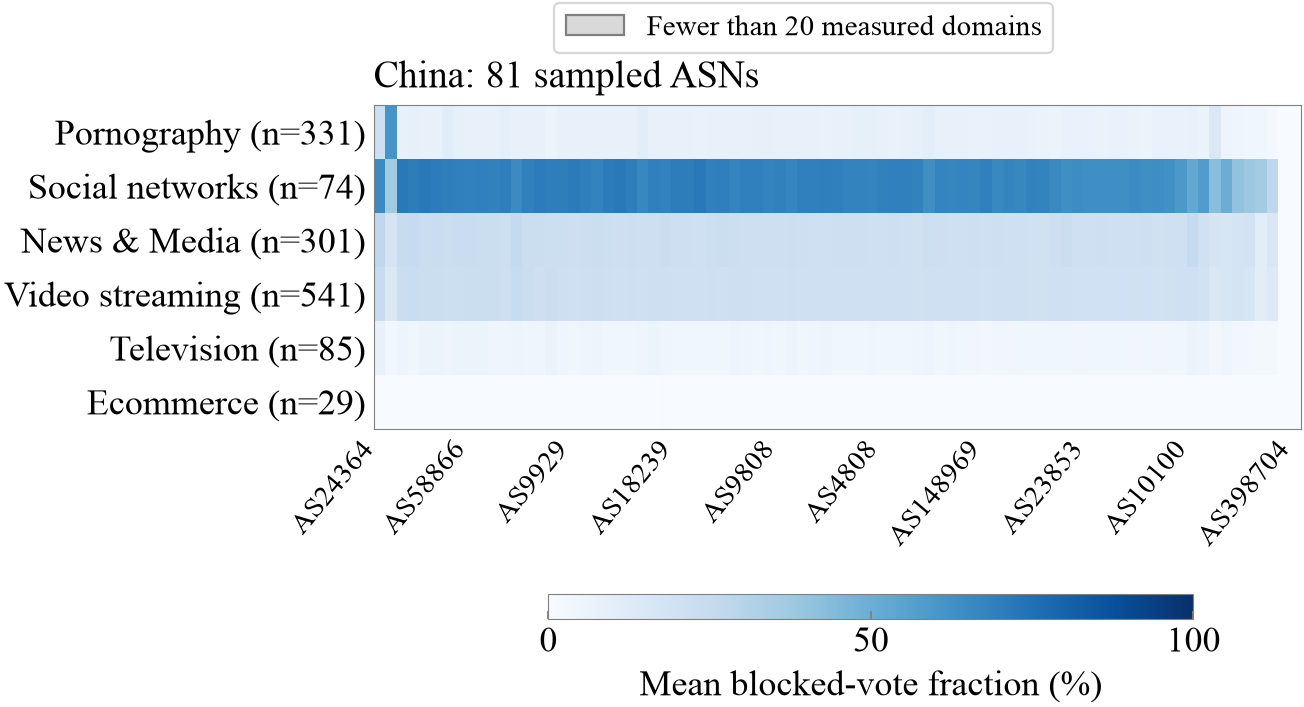

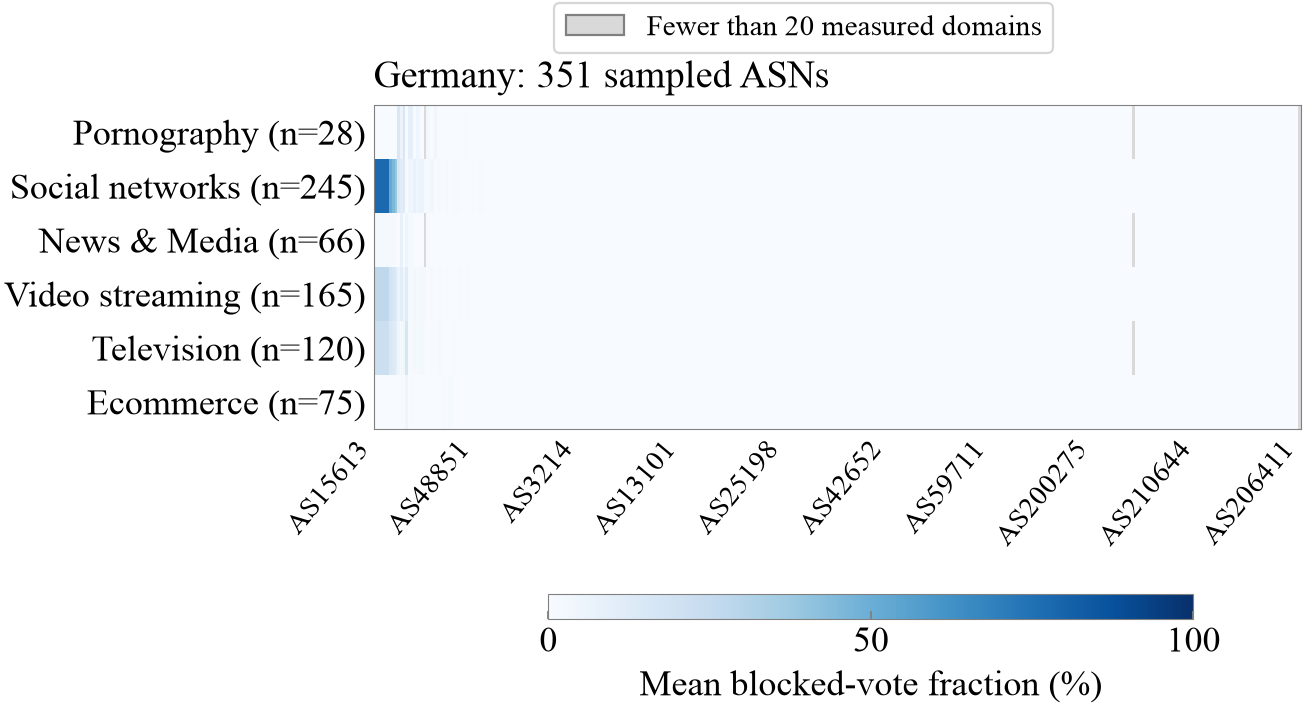

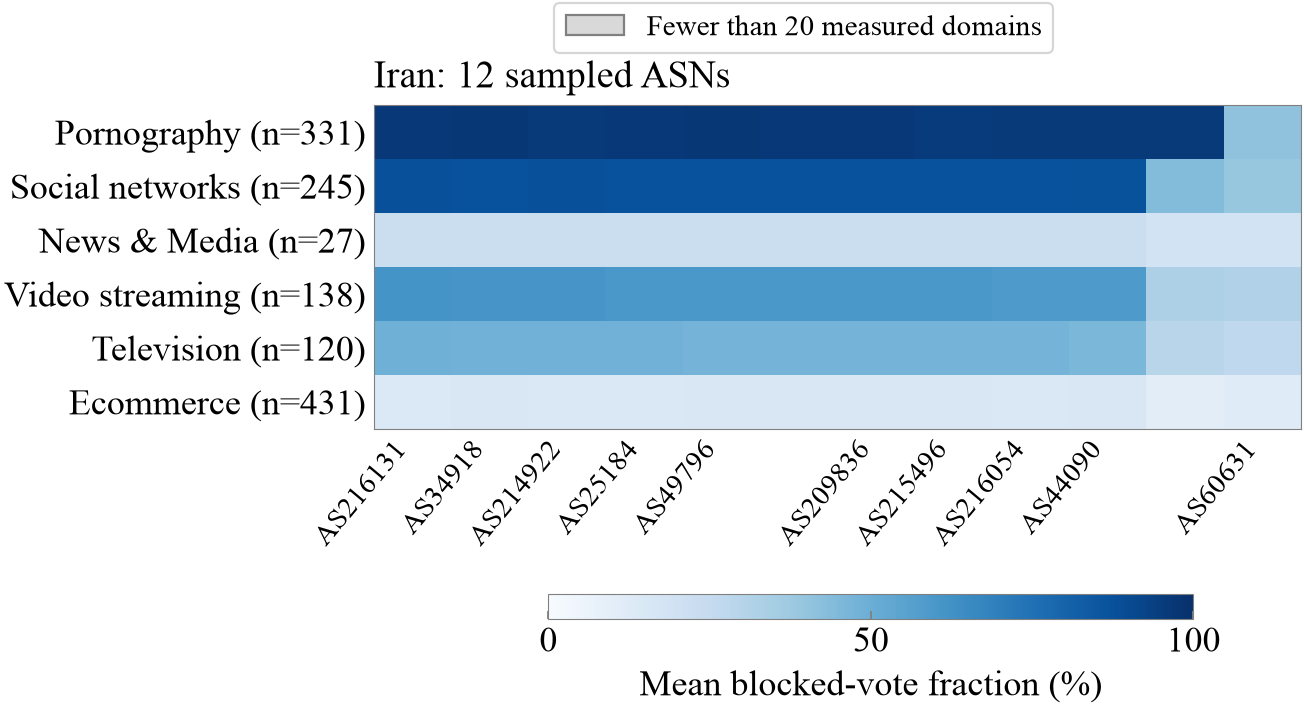

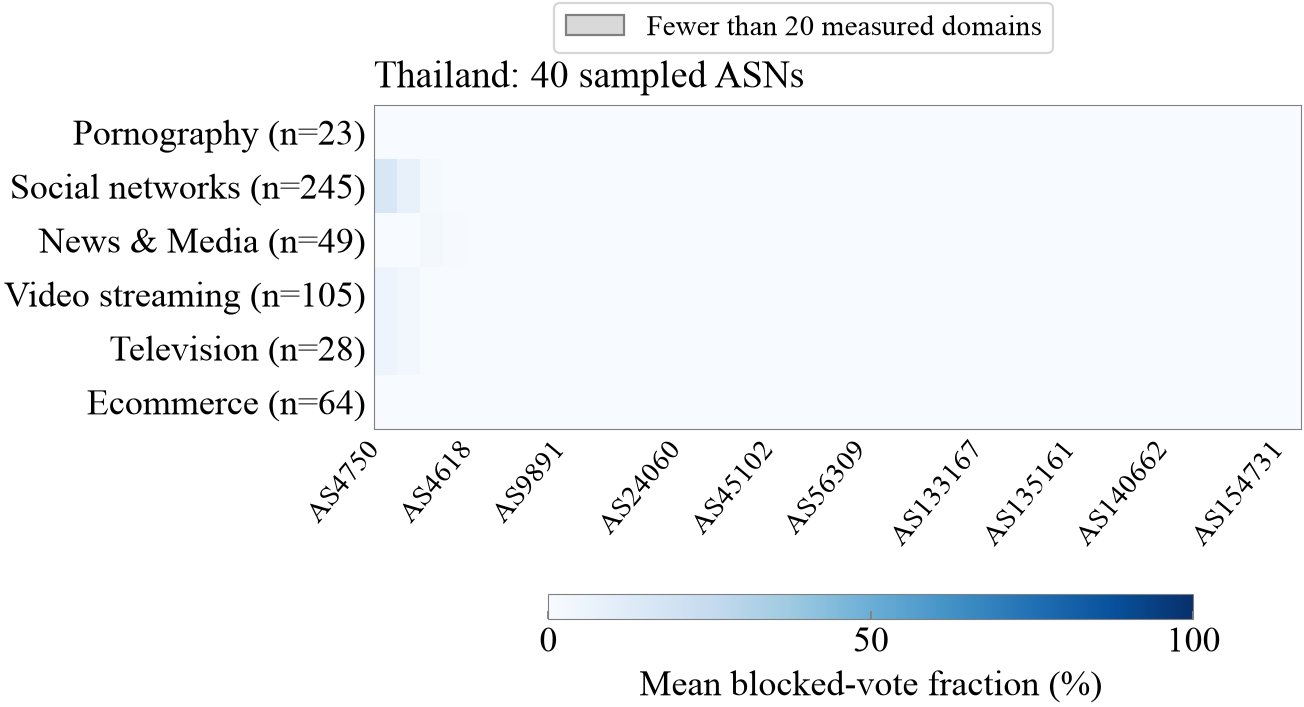

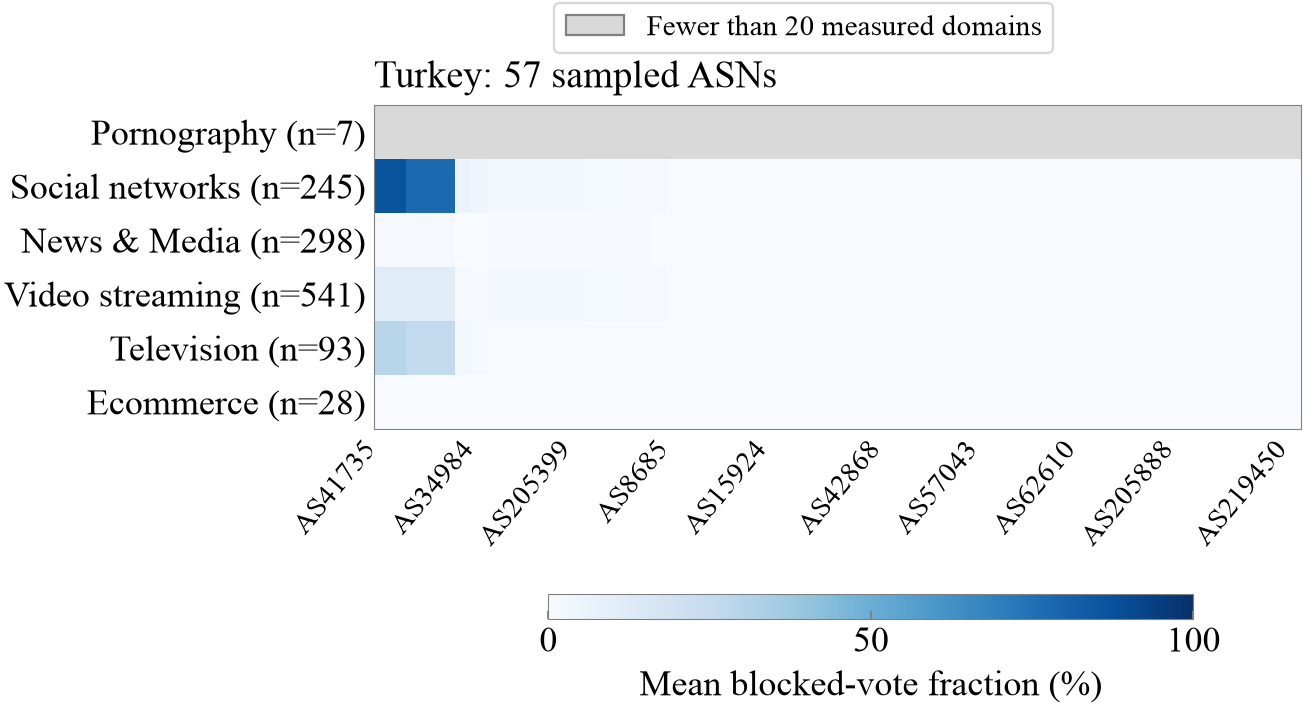

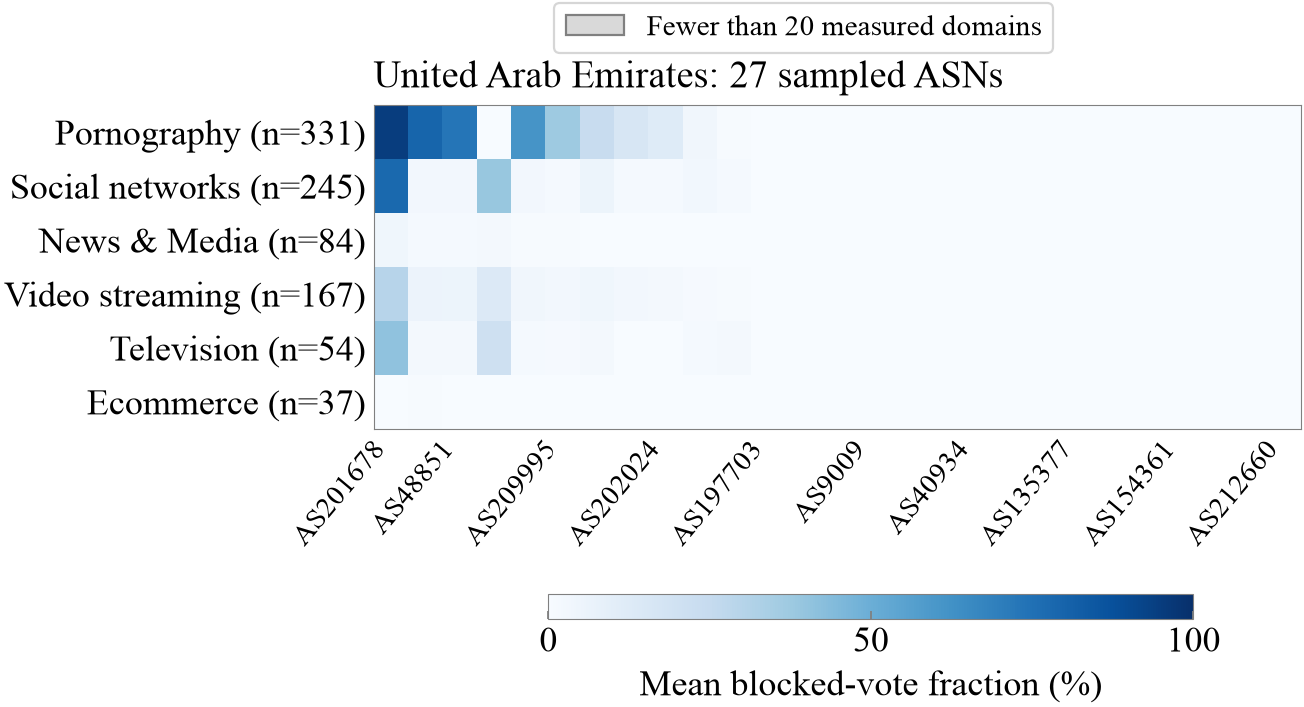

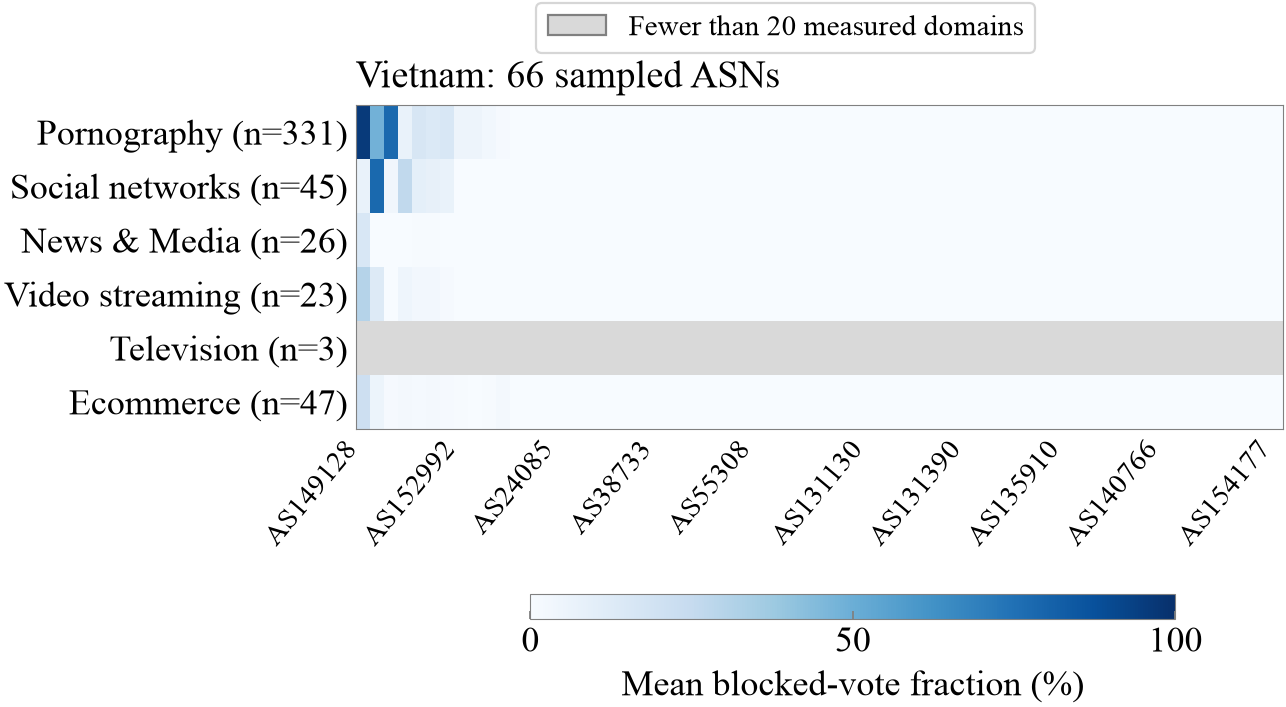

In [18]:
# All countries, with sampled ASN identifiers and the same color scale.
from matplotlib.backends.backend_pdf import PdfPages

with PdfPages(FIGS / "asn_blocking_all_countries.pdf") as all_country_pdf:
    for country in COUNTRIES:
        order = asn_ordering.loc[asn_ordering["country"].eq(country), "asn"].tolist()
        cells = asn_category[asn_category["country"].eq(country)]
        rates = cells.pivot(index="categories", columns="asn", values="mean_fraction").reindex(
            index=ASN_CATEGORIES, columns=order)
        sizes = cells.pivot(index="categories", columns="asn", values="targets").reindex(
            index=ASN_CATEGORIES, columns=order)
        shown = rates.where(sizes.ge(MIN_ASN_TARGETS)) * 100
        row_sizes = asn_heatmap_samples[asn_heatmap_samples["country"].eq(country)].set_index("categories")
        labels = [f"{label} (n={int(row_sizes.loc[category, 'measured_domains'])})"
                  for category, label in zip(ASN_CATEGORIES, asn_row_labels)]
        fig, ax = plt.subplots(figsize=(8.4, 4.4))
        image = ax.imshow(shown, aspect="auto", cmap=asn_cmap, norm=asn_norm, interpolation="nearest")
        ticks = np.unique(np.linspace(0, len(order) - 1, min(10, len(order)), dtype=int))
        ax.set(xticks=ticks, yticks=np.arange(len(ASN_CATEGORIES)), yticklabels=labels)
        ax.set_xticklabels([f"AS{str(order[t]).removeprefix('asn:')}" for t in ticks],
                           rotation=50, ha="right", fontsize=13)
        ax.set_title(f"{country.replace('_', ' ')}: {len(order)} sampled ASNs", loc="left", pad=8)
        format_axes(ax)
        ax.tick_params(axis="x", labelsize=13)
        ax.tick_params(axis="both", length=0)
        ax.grid(False)
        fig.subplots_adjust(left=.30, right=.99, bottom=.40, top=.86)
        cax = fig.add_axes([.43, .13, .48, .035])
        bar = fig.colorbar(image, cax=cax, orientation="horizontal", ticks=[0, 50, 100])
        bar.set_label("Mean blocked-vote fraction (%)", fontsize=16, labelpad=5)
        format_axes(cax)
        cax.grid(False)
        fig.legend(handles=[Patch(facecolor="#d9d9d9", edgecolor="#808080",
                                  label="Fewer than 20 measured domains")],
                   loc="upper center", bbox_to_anchor=(.62, 1.025), fontsize=13)
        all_country_pdf.savefig(fig, bbox_inches="tight", pad_inches=.025)
        fig.savefig(FIGS / f"asn_blocking_{SHORT[country]}.png", bbox_inches="tight", pad_inches=.025)
        plt.show()
print("Seven-country ASN heatmaps saved; columns and sample sizes are in tables/.")


## Default UCB across sampled ASNs

In [36]:
ASN_VIEW_COUNTRIES = ["China", "Iran", "United_Arab_Emirates"]
ASN_VIEW_CATEGORIES = ["Video Streaming", "Photography", "Pornography", "Social Networks", "Television"]
ASN_VIEW_MIN_TARGETS = 20

asn_view_raw = asn.loc[asn["country"].isin(ASN_VIEW_COUNTRIES),
    ["country", "target", "asn", "n_votes", "n_blocked"]].copy()
asn_view_raw["vote_fraction"] = asn_view_raw["n_blocked"] / asn_view_raw["n_votes"]
assert not asn_view_raw.duplicated(["country", "target", "asn"]).any()
asn_view_default = master[master["config"].eq("exp5") & master["country"].isin(ASN_VIEW_COUNTRIES)]
for country in ASN_VIEW_COUNTRIES:
    assert set(asn_view_raw.loc[asn_view_raw["country"].eq(country), "target"]) == set(
        asn_view_default.loc[asn_view_default["country"].eq(country), "target"])

asn_view_members = asn_view_default[["country", "target", "categories"]].explode("categories")
asn_view_members = asn_view_members[asn_view_members["categories"].isin(ASN_VIEW_CATEGORIES)]
assert not asn_view_members.duplicated(["country", "target", "categories"]).any()
asn_view_votes = asn_view_raw.merge(asn_view_members, on=["country", "target"],
                                    how="inner", validate="many_to_many")
assert not asn_view_votes.duplicated(["country", "target", "asn", "categories"]).any()
asn_view_cells = asn_view_votes.groupby(["country", "categories", "asn"], observed=True).agg(
    targets=("target", "nunique"), mean_fraction=("vote_fraction", "mean"),
    votes=("n_votes", "sum"), blocked_votes=("n_blocked", "sum")).reset_index()
assert len(asn_view_cells) == 600
asn_view_cells["pooled_fraction"] = asn_view_cells["blocked_votes"] / asn_view_cells["votes"]
asn_view_cells["displayed"] = asn_view_cells["targets"].ge(ASN_VIEW_MIN_TARGETS)
asn_view_cells.to_csv(TABLES / "asn_country_cells.csv", index=False)

asn_view_columns = asn_view_cells[asn_view_cells["displayed"]].groupby(
    ["country", "asn"], observed=True)["mean_fraction"].mean().rename("sort_score").reset_index()
asn_view_columns["asn_number"] = asn_view_columns["asn"].astype(str).str.removeprefix("asn:").astype(int)
asn_view_columns = asn_view_columns.sort_values(["country", "sort_score", "asn_number"],
                                               ascending=[True, False, True])
asn_view_columns["column"] = asn_view_columns.groupby("country", observed=True).cumcount()
asn_view_columns.to_csv(TABLES / "asn_country_columns.csv", index=False)
asn_view_samples = asn_view_members.groupby(["country", "categories"], observed=True).agg(
    measured_domains=("target", "nunique")).reset_index().merge(
    asn_view_cells.groupby(["country", "categories"], observed=True).agg(
        asns=("asn", "nunique"), min_cell_domains=("targets", "min"),
        max_cell_domains=("targets", "max")), on=["country", "categories"], validate="one_to_one")
asn_view_samples.to_csv(TABLES / "asn_country_samples.csv", index=False)
asn_view_summary = asn_view_cells[asn_view_cells["displayed"]].groupby(
    ["country", "categories"], observed=True).agg(
    asns=("asn", "nunique"), minimum=("mean_fraction", "min"), median=("mean_fraction", "median"),
    maximum=("mean_fraction", "max"), zero_asns=("mean_fraction", lambda x: x.eq(0).sum()),
    above_half_asns=("mean_fraction", lambda x: x.gt(.5).sum())).reset_index()
asn_view_summary.to_csv(TABLES / "asn_country_summary.csv", index=False)

# Keep the difference between exported and online vote counts visible.
asn_view_audit_targets = asn_view_raw.groupby(["country", "target"], observed=True).agg(
    exported_votes=("n_votes", "sum"), exported_blocked=("n_blocked", "sum")).reset_index().merge(
    asn_view_default[["country", "target", "vp_count", "reward", "blocked"]],
    on=["country", "target"], validate="one_to_one")
asn_view_audit_targets["count_mismatch"] = asn_view_audit_targets["exported_votes"].ne(
    asn_view_audit_targets["vp_count"])
asn_view_audit_targets["fraction_mismatch"] = (
    asn_view_audit_targets["exported_blocked"] / asn_view_audit_targets["exported_votes"] -
    asn_view_audit_targets["reward"]).abs().gt(.005001)
assert (2 * asn_view_audit_targets["exported_blocked"]).gt(
    asn_view_audit_targets["exported_votes"]).eq(asn_view_audit_targets["blocked"].astype(bool)).all()
asn_view_audit = asn_view_audit_targets.groupby("country", observed=True).agg(
    targets=("target", "size"), count_mismatches=("count_mismatch", "sum"),
    fraction_mismatches=("fraction_mismatch", "sum")).reset_index()
asn_view_audit.to_csv(TABLES / "asn_country_audit.csv", index=False)
display(asn_view_samples)
display(asn_view_audit)


,country,categories,measured_domains,asns,min_cell_domains,max_cell_domains
0,China,Photography,85,81,85,85
1,China,Pornography,331,81,331,331
2,China,Social Networks,74,81,74,74
3,China,Television,85,81,85,85
4,China,Video Streaming,541,81,541,541
5,Iran,Photography,47,12,44,47
6,Iran,Pornography,331,12,331,331
7,Iran,Social Networks,245,12,245,245
8,Iran,Television,120,12,120,120
9,Iran,Video Streaming,138,12,138,138


,country,targets,count_mismatches,fraction_mismatches
0,China,2000,928,127
1,Iran,2000,14,6
2,United_Arab_Emirates,2000,124,10


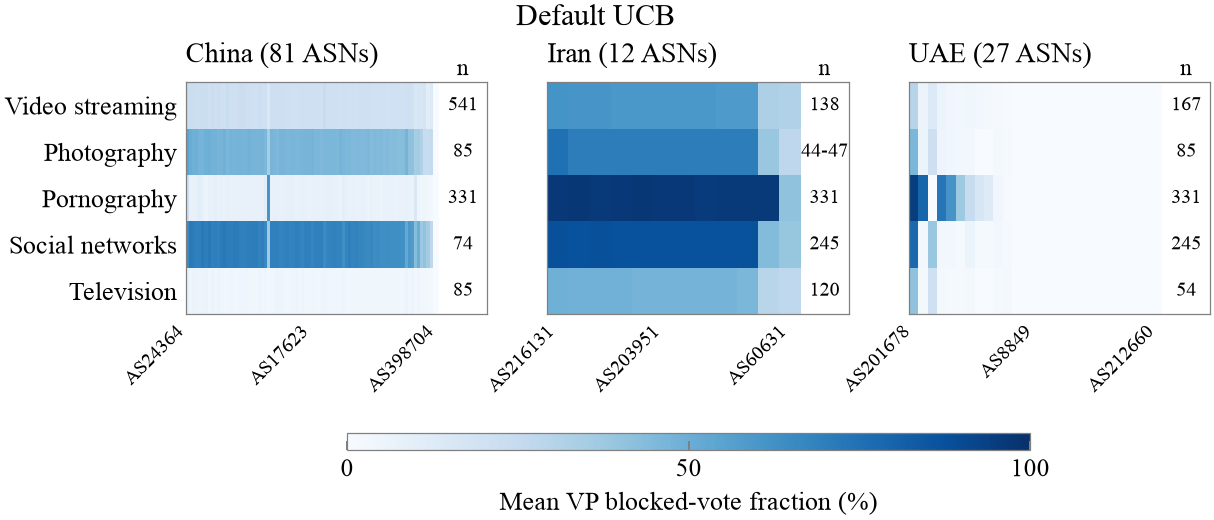

In [37]:
from matplotlib.colors import Normalize
import shutil

asn_view_cmap = mpl.colormaps["Blues"].with_extremes(bad="#d9d9d9")
asn_view_norm = Normalize(0, 100)
asn_view_row_labels = ["Video streaming", "Photography", "Pornography", "Social networks", "Television"]
fig, axes = plt.subplots(1, 3, figsize=(6.9, 2.8), sharey=True)
for ax, country in zip(axes, ASN_VIEW_COUNTRIES):
    order = asn_view_columns.loc[asn_view_columns["country"].eq(country), "asn"].tolist()
    cells = asn_view_cells[asn_view_cells["country"].eq(country)]
    rates = cells.pivot(index="categories", columns="asn", values="mean_fraction").reindex(
        index=ASN_VIEW_CATEGORIES, columns=order)
    sizes = cells.pivot(index="categories", columns="asn", values="targets").reindex(
        index=ASN_VIEW_CATEGORIES, columns=order)
    shown = rates.where(sizes.ge(ASN_VIEW_MIN_TARGETS)) * 100
    mesh = ax.imshow(shown, aspect="auto", cmap=asn_view_cmap, norm=asn_view_norm,
                     interpolation="nearest")
    gutter = .19 * len(order)
    ax.set_xlim(-.5, len(order) - .5 + gutter)
    ticks = np.unique(np.linspace(0, len(order) - 1, 3, dtype=int))
    ax.set(xticks=ticks, yticks=np.arange(len(ASN_VIEW_CATEGORIES)))
    ax.set_xticklabels(["AS" + str(order[i]).removeprefix("asn:") for i in ticks],
                       rotation=45, ha="right", fontsize=8)
    if country == ASN_VIEW_COUNTRIES[0]:
        ax.set_yticklabels(asn_view_row_labels, fontsize=10.5)
    for i in range(len(ASN_VIEW_CATEGORIES)):
        lo, hi = int(sizes.iloc[i].min()), int(sizes.iloc[i].max())
        label = str(lo) if lo == hi else f"{lo}-{hi}"
        ax.text(len(order) - .5 + gutter / 2, i, label, ha="center", va="center", fontsize=8)
    ax.text(len(order) - .5 + gutter / 2, -.77, "n", ha="center", va="center", fontsize=9)
    ax.set_title(f"{COUNTRY_TITLES[country]} ({len(order)} ASNs)", loc="left", fontsize=11, pad=8)
    format_axes(ax)
    ax.grid(False)
    ax.tick_params(axis="both", length=0, labelsize=10.5)
    ax.tick_params(axis="x", labelsize=8)
fig.suptitle("Default UCB", fontsize=12, y=1.005)
fig.subplots_adjust(left=.17, right=.995, bottom=.39, top=.85, wspace=.20)
cax = fig.add_axes([.30, .12, .55, .035])
bar = fig.colorbar(mesh, cax=cax, orientation="horizontal", ticks=[0, 50, 100])
bar.set_label("Mean VP blocked-vote fraction (%)", fontsize=10.5, labelpad=4)
format_axes(cax)
cax.grid(False)
cax.tick_params(labelsize=10)
for extension in ["pdf", "png"]:
    fig.savefig(FIGS / f"05_asn_blocking_countries.{extension}", bbox_inches="tight", pad_inches=.025)
paper_figures = ANALYSIS.parent / "paper" / "figures"
shutil.copyfile(FIGS / "05_asn_blocking_countries.pdf", paper_figures / "results_asn_blocking.pdf")
plt.show()
